In [2]:
import os
import requests
from google.colab import userdata

# Retrieve Kaggle API token securely
kaggle_token = userdata.get("KAGGLE_API_TOKEN")

if not kaggle_token:
    raise ValueError("KAGGLE_API_TOKEN was not found in Colab Secrets.")

# Verify Kaggle API authentication
response = requests.get(
    "https://www.kaggle.com/api/v1/datasets/list",
    headers={"Authorization": f"Bearer {kaggle_token}"},
    params={"page": 1, "pageSize": 1},
    timeout=30
)

print("HTTP Status:", response.status_code)

if response.status_code == 200:
    print("Kaggle API authentication successful.")
elif response.status_code == 401:
    print("Authentication failed. Check your API token.")
else:
    print("API request failed:", response.text[:300])

HTTP Status: 200
Kaggle API authentication successful.


In [3]:

import os
import requests
import zipfile
from pathlib import Path
from google.colab import userdata

# Configuration
DATASET_SLUG = "andradaolteanu/gtzan-dataset-music-genre-classification"
BASE_DIR = Path("/content/datasets")
ZIP_PATH = BASE_DIR / "gtzan_dataset.zip"
EXTRACT_DIR = BASE_DIR / "gtzan"

BASE_DIR.mkdir(parents=True, exist_ok=True)

# Retrieve credentials securely
token = userdata.get("KAGGLE_API_TOKEN")

if not token:
    raise ValueError("Kaggle API token not found.")

# Download dataset
url = f"https://www.kaggle.com/api/v1/datasets/download/{DATASET_SLUG}"

print("Starting GTZAN dataset download...")

response = requests.get(
    url,
    headers={"Authorization": f"Bearer {token}"},
    stream=True,
    timeout=(30, 120)
)

response.raise_for_status()

total_size = int(response.headers.get("content-length", 0))
downloaded = 0

with open(ZIP_PATH, "wb") as file:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            file.write(chunk)
            downloaded += len(chunk)

            if total_size:
                progress = downloaded / total_size * 100
                print(
                    f"\rDownloaded: {progress:.1f}% "
                    f"({downloaded / 1024**2:.1f} MB)",
                    end=""
                )

print("\nDownload completed.")

print(f"Archive size: {ZIP_PATH.stat().st_size / 1024**2:.2f} MB")

# Extract dataset
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

print("\nExtracting dataset...")

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(EXTRACT_DIR)

print("Extraction completed.")

# Display extracted directory structure
print("\nDataset root contents:")

for item in sorted(EXTRACT_DIR.iterdir()):
    print(f"{'[DIR]' if item.is_dir() else '[FILE]'} {item.name}")

print("\nDataset location:", EXTRACT_DIR)


Starting GTZAN dataset download...
Downloaded: 100.0% (1241.2 MB)
Download completed.
Archive size: 1241.20 MB

Extracting dataset...
Extraction completed.

Dataset root contents:
[DIR] Data

Dataset location: /content/datasets/gtzan


In [4]:

from pathlib import Path
from collections import Counter, defaultdict

DATASET_DIR = Path("/content/datasets/gtzan/Data")

if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Dataset directory not found: {DATASET_DIR}")

# Collect all files
all_files = [p for p in DATASET_DIR.rglob("*") if p.is_file()]

print("=" * 65)
print("GTZAN DATASET STRUCTURE")
print("=" * 65)

print(f"\nTotal files: {len(all_files)}")
print(f"Total directories: {sum(1 for p in DATASET_DIR.rglob('*') if p.is_dir())}")

# File extensions
extensions = Counter(p.suffix.lower() or "[no extension]" for p in all_files)

print("\nFile Extensions:")
for ext, count in sorted(extensions.items()):
    print(f"{ext}: {count}")

# Directory-level file counts
print("\nTop-level directories:")

for directory in sorted(p for p in DATASET_DIR.iterdir() if p.is_dir()):
    files = [p for p in directory.rglob("*") if p.is_file()]
    print(f"\n{directory.name}: {len(files)} files")

    for child in sorted(directory.iterdir())[:15]:
        if child.is_dir():
            child_count = sum(1 for p in child.rglob("*") if p.is_file())
            print(f"  [DIR]  {child.name}: {child_count} files")
        else:
            print(f"  [FILE] {child.name}")

# Audio file inventory
audio_extensions = {".wav", ".mp3", ".flac", ".ogg", ".m4a"}
audio_files = [p for p in all_files if p.suffix.lower() in audio_extensions]

print("\n" + "=" * 65)
print("AUDIO INVENTORY")
print("=" * 65)

print(f"Total detected audio files: {len(audio_files)}")

genre_counts = defaultdict(int)

for audio_file in audio_files:
    genre_counts[audio_file.parent.name] += 1

print("\nAudio files by immediate parent directory:")

for genre, count in sorted(genre_counts.items()):
    print(f"{genre}: {count}")

# Show sample paths
print("\nSample audio paths:")

for path in audio_files[:10]:
    print(path.relative_to(DATASET_DIR))


GTZAN DATASET STRUCTURE

Total files: 2001
Total directories: 22

File Extensions:
.csv: 2
.png: 999
.wav: 1000

Top-level directories:

genres_original: 1000 files
  [DIR]  blues: 100 files
  [DIR]  classical: 100 files
  [DIR]  country: 100 files
  [DIR]  disco: 100 files
  [DIR]  hiphop: 100 files
  [DIR]  jazz: 100 files
  [DIR]  metal: 100 files
  [DIR]  pop: 100 files
  [DIR]  reggae: 100 files
  [DIR]  rock: 100 files

images_original: 999 files
  [DIR]  blues: 100 files
  [DIR]  classical: 100 files
  [DIR]  country: 100 files
  [DIR]  disco: 100 files
  [DIR]  hiphop: 100 files
  [DIR]  jazz: 99 files
  [DIR]  metal: 100 files
  [DIR]  pop: 100 files
  [DIR]  reggae: 100 files
  [DIR]  rock: 100 files

AUDIO INVENTORY
Total detected audio files: 1000

Audio files by immediate parent directory:
blues: 100
classical: 100
country: 100
disco: 100
hiphop: 100
jazz: 100
metal: 100
pop: 100
reggae: 100
rock: 100

Sample audio paths:
genres_original/country/country.00053.wav
genres_or

In [5]:

import hashlib
import numpy as np
import pandas as pd
import soundfile as sf

from pathlib import Path
from collections import Counter

AUDIO_DIR = Path("/content/datasets/gtzan/Data/genres_original")

audio_files = sorted(AUDIO_DIR.rglob("*.wav"))

results = []
corrupted_files = []

print(f"Inspecting {len(audio_files)} audio files...\n")

for index, file_path in enumerate(audio_files, start=1):
    try:
        info = sf.info(str(file_path))

        # Calculate file hash for exact duplicate detection
        file_hash = hashlib.sha256(file_path.read_bytes()).hexdigest()

        results.append({
            "filename": file_path.name,
            "genre": file_path.parent.name,
            "sample_rate": info.samplerate,
            "channels": info.channels,
            "duration": info.duration,
            "frames": info.frames,
            "format": info.format,
            "subtype": info.subtype,
            "file_size_mb": file_path.stat().st_size / (1024 ** 2),
            "sha256": file_hash
        })

    except Exception as error:
        corrupted_files.append({
            "file": str(file_path),
            "error": str(error)
        })

    if index % 100 == 0:
        print(f"Processed: {index}/{len(audio_files)}")

# Create DataFrame
audio_df = pd.DataFrame(results)

print("\n" + "=" * 60)
print("AUDIO INTEGRITY REPORT")
print("=" * 60)

print(f"\nReadable files: {len(audio_df)}")
print(f"Corrupted/unreadable files: {len(corrupted_files)}")

if not audio_df.empty:
    print("\nSample Rate Distribution:")
    print(audio_df["sample_rate"].value_counts().sort_index())

    print("\nChannel Distribution:")
    print(audio_df["channels"].value_counts().sort_index())

    print("\nAudio Format Distribution:")
    print(audio_df["format"].value_counts())

    print("\nDuration Statistics:")
    print(audio_df["duration"].describe().round(3))

    print("\nFile Size Statistics (MB):")
    print(audio_df["file_size_mb"].describe().round(3))

    print("\nDuration Range by Genre:")
    print(
        audio_df.groupby("genre")["duration"]
        .agg(["min", "max", "mean"])
        .round(3)
    )

    # Detect exact duplicate files
    duplicate_groups = (
        audio_df.groupby("sha256")
        .filter(lambda group: len(group) > 1)
    )

    print("\nExact Duplicate Files:")
    if duplicate_groups.empty:
        print("No exact duplicates detected.")
    else:
        print(
            duplicate_groups[
                ["filename", "genre", "sha256"]
            ].to_string(index=False)
        )

    # Detect suspicious duration differences
    print("\nFiles with unusual duration (<= 1 sec or > 60 sec):")
    unusual = audio_df[
        (audio_df["duration"] <= 1) |
        (audio_df["duration"] > 60)
    ]

    print(unusual[["filename", "genre", "duration"]].to_string(index=False))

if corrupted_files:
    print("\nCorrupted File Details:")
    for item in corrupted_files:
        print(item)

# Save inspection report
REPORT_DIR = Path("/content/datasets/reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

audio_df.to_csv(
    REPORT_DIR / "audio_integrity_report.csv",
    index=False
)

print("\nReport saved to:", REPORT_DIR / "audio_integrity_report.csv")


Inspecting 1000 audio files...

Processed: 100/1000
Processed: 200/1000
Processed: 300/1000
Processed: 400/1000
Processed: 500/1000
Processed: 600/1000
Processed: 700/1000
Processed: 800/1000
Processed: 900/1000
Processed: 1000/1000

AUDIO INTEGRITY REPORT

Readable files: 999
Corrupted/unreadable files: 1

Sample Rate Distribution:
sample_rate
22050    999
Name: count, dtype: int64

Channel Distribution:
channels
1    999
Name: count, dtype: int64

Audio Format Distribution:
format
WAV    999
Name: count, dtype: int64

Duration Statistics:
count    999.000
mean      30.024
std        0.081
min       29.932
25%       30.000
50%       30.013
75%       30.013
max       30.649
Name: duration, dtype: float64

File Size Statistics (MB):
count    999.000
mean       1.263
std        0.003
min        1.259
25%        1.262
50%        1.262
75%        1.262
max        1.289
Name: file_size_mb, dtype: float64

Duration Range by Genre:
              min     max    mean
genre                      

In [6]:

import pandas as pd
from pathlib import Path

# Group identical audio files by SHA-256
duplicate_groups = (
    audio_df.groupby("sha256")
    .filter(lambda group: len(group) > 1)
    .sort_values(["sha256", "genre", "filename"])
)

print("=" * 65)
print("EXACT DUPLICATE ANALYSIS")
print("=" * 65)

groups = audio_df.groupby("sha256")

duplicate_hashes = [
    (sha, group)
    for sha, group in groups
    if len(group) > 1
]

print(f"\nReadable audio files: {len(audio_df)}")
print(f"Unique audio hashes: {audio_df['sha256'].nunique()}")
print(f"Duplicate hash groups: {len(duplicate_hashes)}")
print(f"Files involved in duplicates: {len(duplicate_groups)}")

same_label_groups = 0
cross_label_groups = 0

print("\nDetailed Duplicate Groups:\n")

for index, (sha, group) in enumerate(duplicate_hashes, start=1):
    genres = sorted(group["genre"].unique())

    if len(genres) == 1:
        same_label_groups += 1
        group_type = "SAME GENRE"
    else:
        cross_label_groups += 1
        group_type = "CROSS GENRE - LABEL CONFLICT"

    print(f"Group {index}: {group_type}")
    print(f"SHA256: {sha}")
    print(f"Genres: {genres}")

    for _, row in group.iterrows():
        print(f"  - {row['genre']}/{row['filename']}")

    print()

print("=" * 65)
print("DUPLICATE SUMMARY")
print("=" * 65)

print(f"Same-label duplicate groups: {same_label_groups}")
print(f"Cross-label duplicate groups: {cross_label_groups}")

print("\nUnique samples per genre (before cleaning):")

print(
    audio_df.groupby("genre")["sha256"]
    .nunique()
    .sort_index()
)

# Identify the corrupted file from the previous inspection
corrupted_path = (
    Path("/content/datasets/gtzan/Data/genres_original/jazz/jazz.00054.wav")
)

print("\nCorrupted file exists:", corrupted_path.exists())

print("\nNo files have been modified or deleted.")


EXACT DUPLICATE ANALYSIS

Readable audio files: 999
Unique audio hashes: 985
Duplicate hash groups: 14
Files involved in duplicates: 28

Detailed Duplicate Groups:

Group 1: SAME GENRE
SHA256: 2301f6e86dfd5bb4d58cf5bd6bacdf1a1c6e3aa727dfd366afd85c7d63aad8bf
Genres: ['pop']
  - pop/pop.00067.wav
  - pop/pop.00071.wav

Group 2: SAME GENRE
SHA256: 3496655d22b1ea1efd55457192b5a78547e71c868dc952dccef883191569804f
Genres: ['disco']
  - disco/disco.00098.wav
  - disco/disco.00099.wav

Group 3: SAME GENRE
SHA256: 44fd895ac99797974552a10640f9be9d11742f536ed87ef19d0329834a48d41a
Genres: ['hiphop']
  - hiphop/hiphop.00076.wav
  - hiphop/hiphop.00078.wav

Group 4: SAME GENRE
SHA256: 4de67c0fd52ad616a56a790916ab2a895893cde730d916b935b4b07e1fcae2a0
Genres: ['metal']
  - metal/metal.00045.wav
  - metal/metal.00066.wav

Group 5: CROSS GENRE - LABEL CONFLICT
SHA256: 56e2b93b263a1f29ced0090d615d40755e9dc19b8066234355cfbb4ffcc2f019
Genres: ['metal', 'rock']
  - metal/metal.00058.wav
  - rock/rock.00016.w

In [7]:
import pandas as pd
from pathlib import Path

# Dataset paths
DATASET_DIR = Path("/content/datasets/gtzan/Data")
GENRES_DIR = DATASET_DIR / "genres_original"
REPORTS_DIR = Path("/content/datasets/reports")

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Build a manifest from the integrity report
manifest = audio_df.copy()

manifest["file_path"] = manifest.apply(
    lambda row: str(
        GENRES_DIR / row["genre"] / row["filename"]
    ),
    axis=1
)

manifest["status"] = "KEEP"
manifest["exclusion_reason"] = ""

# Exclude corrupted audio
corrupted_path = (
    GENRES_DIR / "jazz" / "jazz.00054.wav"
)

manifest.loc[
    manifest["file_path"] == str(corrupted_path),
    ["status", "exclusion_reason"]
] = ["EXCLUDE", "Corrupted Audio"]

# Process exact duplicate groups
for sha, group in manifest.groupby("sha256"):

    if len(group) <= 1:
        continue

    genres = group["genre"].unique()

    # Conflicting labels: exclude the entire group
    if len(genres) > 1:
        manifest.loc[
            group.index,
            ["status", "exclusion_reason"]
        ] = ["EXCLUDE", "Exact Duplicate - Label Conflict"]

    else:
        # Keep one representative deterministically
        sorted_indices = group.sort_values(
            "filename"
        ).index

        keep_index = sorted_indices[0]
        duplicate_indices = sorted_indices[1:]

        manifest.loc[
            duplicate_indices,
            ["status", "exclusion_reason"]
        ] = ["EXCLUDE", "Exact Duplicate - Same Label"]

# Save manifest
manifest_path = REPORTS_DIR / "clean_dataset_manifest.csv"
manifest.to_csv(manifest_path, index=False)

# Summary
print("=" * 60)
print("CLEAN DATASET MANIFEST")
print("=" * 60)

print("\nStatus:")
print(manifest["status"].value_counts())

print("\nExclusion reasons:")
print(
    manifest.loc[
        manifest["status"] == "EXCLUDE",
        "exclusion_reason"
    ].value_counts()
)

print("\nFinal samples per genre:")
print(
    manifest[manifest["status"] == "KEEP"]
    .groupby("genre")
    .size()
    .sort_index()
)

print("\nTotal kept:", (manifest["status"] == "KEEP").sum())
print("Total excluded:", (manifest["status"] == "EXCLUDE").sum())

print("\nManifest saved to:", manifest_path)

# Verify that original audio files still exist
print(
    "\nOriginal audio files preserved:",
    all(Path(p).exists() for p in manifest["file_path"])
)

CLEAN DATASET MANIFEST

Status:
status
KEEP       984
EXCLUDE     15
Name: count, dtype: int64

Exclusion reasons:
exclusion_reason
Exact Duplicate - Same Label        13
Exact Duplicate - Label Conflict     2
Name: count, dtype: int64

Final samples per genre:
genre
blues        100
classical    100
country      100
disco         99
hiphop        98
jazz          99
metal         92
pop           98
reggae        99
rock          99
dtype: int64

Total kept: 984
Total excluded: 15

Manifest saved to: /content/datasets/reports/clean_dataset_manifest.csv

Original audio files preserved: True


AUDIO DATASET EXPLORATORY ANALYSIS

Total clean samples: 984
Number of genres: 10

Audio duration statistics:
count    984.000
mean      30.024
std        0.079
min       29.932
25%       30.000
50%       30.013
75%       30.013
max       30.649
Name: duration, dtype: float64

Sample rate distribution:
sample_rate
22050    984
Name: count, dtype: int64

Channel distribution:
channels
1    984
Name: count, dtype: int64

Audio format distribution:
format
WAV    984
Name: count, dtype: int64


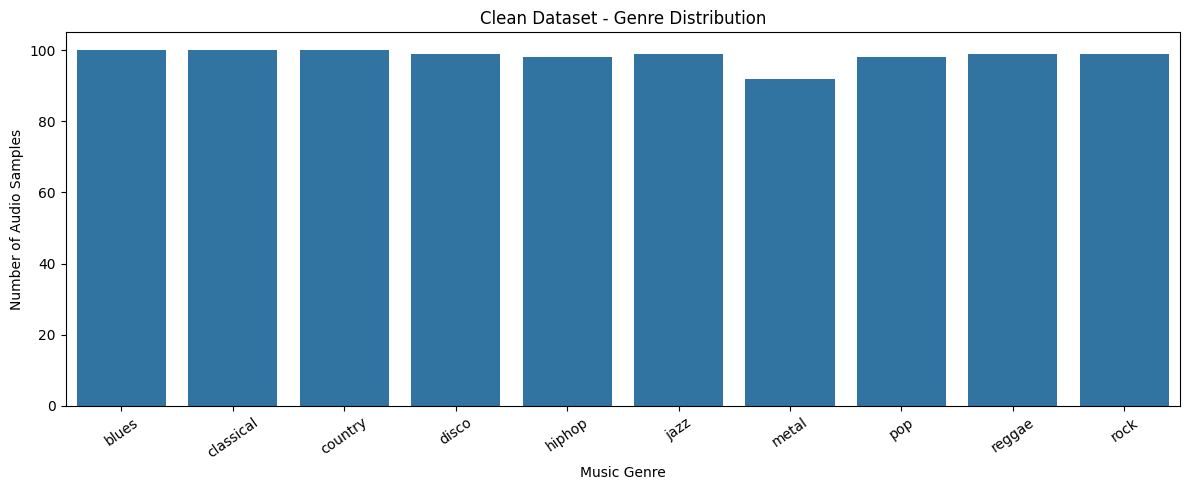

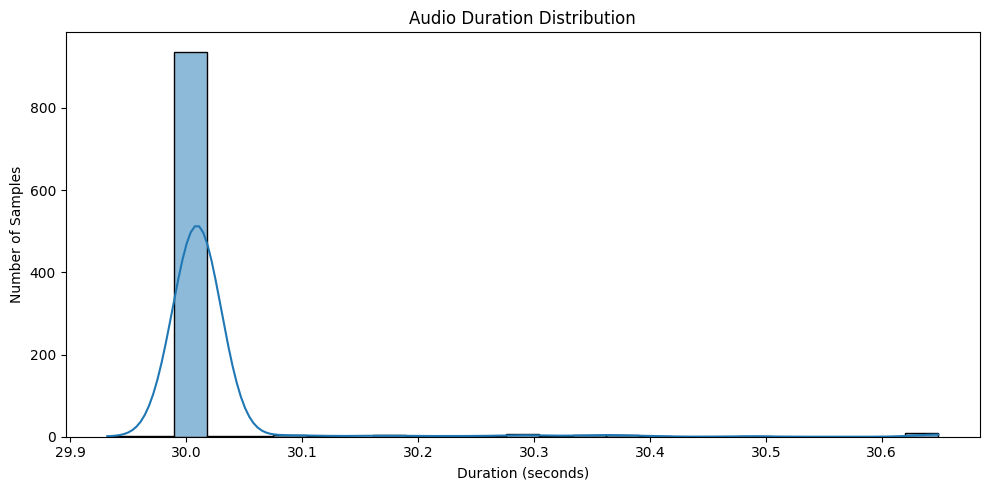

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use only clean samples
clean_df = manifest[manifest["status"] == "KEEP"].copy()

# Dataset overview
print("=" * 60)
print("AUDIO DATASET EXPLORATORY ANALYSIS")
print("=" * 60)

print(f"\nTotal clean samples: {len(clean_df)}")
print(f"Number of genres: {clean_df['genre'].nunique()}")

print("\nAudio duration statistics:")
print(clean_df["duration"].describe().round(3))

print("\nSample rate distribution:")
print(clean_df["sample_rate"].value_counts())

print("\nChannel distribution:")
print(clean_df["channels"].value_counts())

print("\nAudio format distribution:")
print(clean_df["format"].value_counts())

# Plot genre distribution
plt.figure(figsize=(12, 5))

sns.countplot(
    data=clean_df,
    x="genre",
    order=sorted(clean_df["genre"].unique())
)

plt.title("Clean Dataset - Genre Distribution")
plt.xlabel("Music Genre")
plt.ylabel("Number of Audio Samples")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# Plot duration distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=clean_df,
    x="duration",
    bins=25,
    kde=True
)

plt.title("Audio Duration Distribution")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

Blues: Duration=30.00s | Sample Rate=22050 | Samples=661500
Classical: Duration=30.00s | Sample Rate=22050 | Samples=661500
Metal: Duration=30.00s | Sample Rate=22050 | Samples=661500


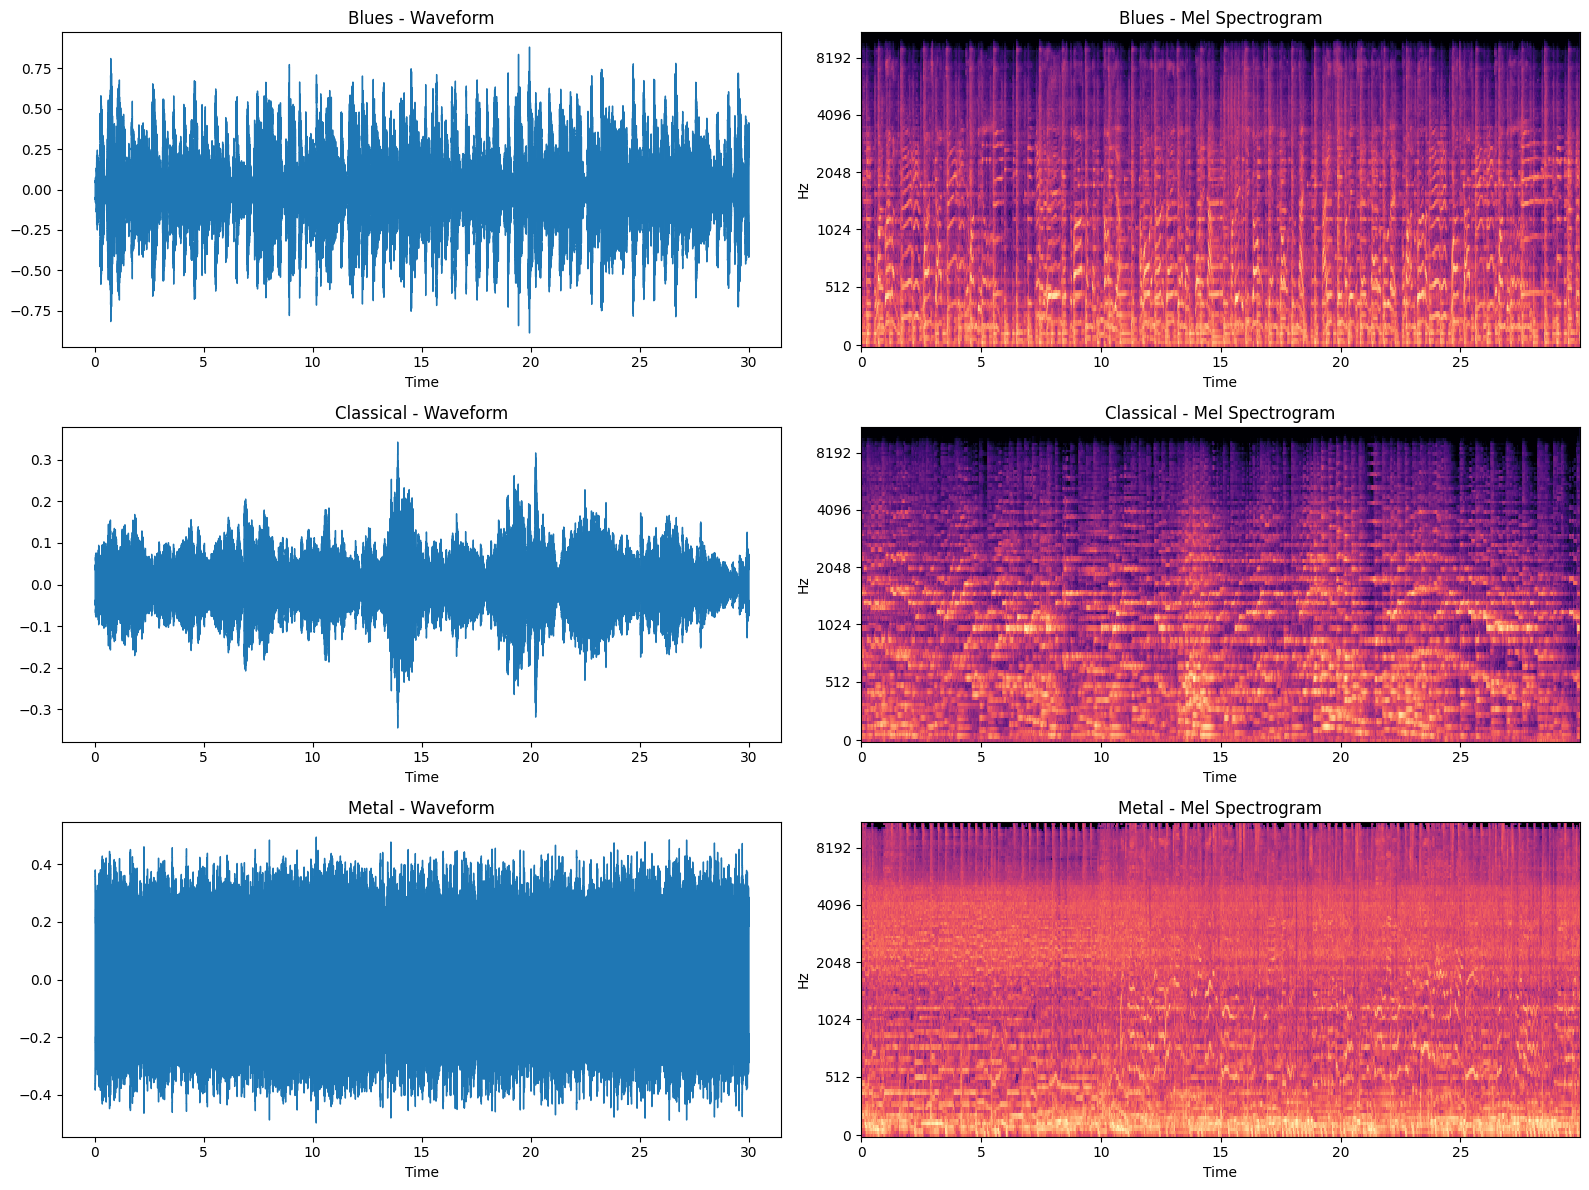

In [9]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Select one clean sample from each genre
sample_files = (
    clean_df.sort_values("filename")
    .groupby("genre")
    .first()
)

genres_to_inspect = ["blues", "classical", "metal"]

fig, axes = plt.subplots(
    len(genres_to_inspect),
    2,
    figsize=(16, 12)
)

for row, genre in enumerate(genres_to_inspect):

    file_path = sample_files.loc[genre, "file_path"]

    # Load audio
    y, sr = librosa.load(
        file_path,
        sr=22050,
        mono=True,
        duration=30
    )

    # Waveform
    librosa.display.waveshow(
        y,
        sr=sr,
        ax=axes[row, 0]
    )

    axes[row, 0].set_title(
        f"{genre.title()} - Waveform"
    )

    # Mel Spectrogram
    mel_spec = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=2048,
        hop_length=512,
        n_mels=128
    )

    mel_db = librosa.power_to_db(
        mel_spec,
        ref=np.max
    )

    librosa.display.specshow(
        mel_db,
        sr=sr,
        hop_length=512,
        x_axis="time",
        y_axis="mel",
        ax=axes[row, 1]
    )

    axes[row, 1].set_title(
        f"{genre.title()} - Mel Spectrogram"
    )

    print(
        f"{genre.title()}: "
        f"Duration={len(y)/sr:.2f}s | "
        f"Sample Rate={sr} | "
        f"Samples={len(y)}"
    )

plt.tight_layout()
plt.show()

In [10]:
import librosa
import numpy as np
import pandas as pd

# Select one clean audio sample
sample_row = clean_df.sort_values("filename").iloc[0]

file_path = sample_row["file_path"]
genre = sample_row["genre"]

# Load audio
y, sr = librosa.load(
    file_path,
    sr=22050,
    mono=True,
    duration=30
)

# Feature extraction
features = {}

# MFCC: 20 coefficients
mfcc = librosa.feature.mfcc(
    y=y,
    sr=sr,
    n_mfcc=20,
    n_fft=2048,
    hop_length=512
)

for i in range(20):
    features[f"mfcc_{i+1}_mean"] = np.mean(mfcc[i])
    features[f"mfcc_{i+1}_std"] = np.std(mfcc[i])

# Chroma
chroma = librosa.feature.chroma_stft(
    y=y,
    sr=sr,
    n_fft=2048,
    hop_length=512
)

features["chroma_mean"] = np.mean(chroma)
features["chroma_std"] = np.std(chroma)

# Spectral features
spectral_centroid = librosa.feature.spectral_centroid(
    y=y, sr=sr, n_fft=2048, hop_length=512
)

spectral_bandwidth = librosa.feature.spectral_bandwidth(
    y=y, sr=sr, n_fft=2048, hop_length=512
)

spectral_rolloff = librosa.feature.spectral_rolloff(
    y=y, sr=sr, n_fft=2048, hop_length=512
)

zcr = librosa.feature.zero_crossing_rate(y, hop_length=512)

rms = librosa.feature.rms(
    y=y,
    frame_length=2048,
    hop_length=512
)

# Mean and standard deviation
for name, values in {
    "spectral_centroid": spectral_centroid,
    "spectral_bandwidth": spectral_bandwidth,
    "spectral_rolloff": spectral_rolloff,
    "zcr": zcr,
    "rms": rms
}.items():

    features[f"{name}_mean"] = np.mean(values)
    features[f"{name}_std"] = np.std(values)

# Display extracted features
feature_df = pd.DataFrame([features])

print("=" * 60)
print("SINGLE AUDIO FEATURE EXTRACTION TEST")
print("=" * 60)

print(f"\nFile: {Path(file_path).name}")
print(f"Genre: {genre}")
print(f"Number of features: {len(features)}")

print("\nExtracted feature values:")
print(feature_df.T.to_string())

print("\nAll values finite:", np.isfinite(feature_df.values).all())

SINGLE AUDIO FEATURE EXTRACTION TEST

File: blues.00000.wav
Genre: blues
Number of features: 52

Extracted feature values:
                                   0
mfcc_1_mean              -113.619385
mfcc_1_std                 50.703182
mfcc_2_mean               121.553032
mfcc_2_std                 17.196640
mfcc_3_mean               -19.151056
mfcc_3_std                 15.348610
mfcc_4_mean                42.345764
mfcc_4_std                 12.281506
mfcc_5_mean                -6.371165
mfcc_5_std                 12.962433
mfcc_6_mean                18.613029
mfcc_6_std                  9.442966
mfcc_7_mean               -13.692058
mfcc_7_std                  8.222214
mfcc_8_mean                15.339376
mfcc_8_std                  8.310419
mfcc_9_mean               -12.283616
mfcc_9_std                  9.063802
mfcc_10_mean               10.973773
mfcc_10_std                 7.962442
mfcc_11_mean               -8.322408
mfcc_11_std                 7.861969
mfcc_12_mean              

In [11]:
import librosa
import numpy as np
from pathlib import Path

def extract_audio_features(file_path, sr=22050):

    y, sr = librosa.load(
        file_path,
        sr=sr,
        mono=True,
        duration=30
    )

    if len(y) == 0:
        raise ValueError(f"Empty audio file: {file_path}")

    features = {}

    # MFCC
    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=20,
        n_fft=2048,
        hop_length=512
    )

    for i in range(20):
        features[f"mfcc_{i+1}_mean"] = float(np.mean(mfcc[i]))
        features[f"mfcc_{i+1}_std"] = float(np.std(mfcc[i]))

    # Chroma
    chroma = librosa.feature.chroma_stft(
        y=y,
        sr=sr,
        n_fft=2048,
        hop_length=512
    )

    features["chroma_mean"] = float(np.mean(chroma))
    features["chroma_std"] = float(np.std(chroma))

    # Spectral features
    spectral_features = {
        "spectral_centroid": librosa.feature.spectral_centroid(
            y=y, sr=sr, n_fft=2048, hop_length=512
        ),
        "spectral_bandwidth": librosa.feature.spectral_bandwidth(
            y=y, sr=sr, n_fft=2048, hop_length=512
        ),
        "spectral_rolloff": librosa.feature.spectral_rolloff(
            y=y, sr=sr, n_fft=2048, hop_length=512
        ),
        "zcr": librosa.feature.zero_crossing_rate(
            y=y, hop_length=512
        ),
        "rms": librosa.feature.rms(
            y=y, frame_length=2048, hop_length=512
        )
    }

    for name, values in spectral_features.items():
        features[f"{name}_mean"] = float(np.mean(values))
        features[f"{name}_std"] = float(np.std(values))

    # Validate output
    feature_values = np.asarray(list(features.values()))

    if not np.isfinite(feature_values).all():
        raise ValueError(f"Non-finite features detected: {file_path}")

    return features


# Test the reusable function
test_features = extract_audio_features(
    clean_df.iloc[0]["file_path"]
)

print("Feature extraction function test")
print("=" * 50)
print("Number of features:", len(test_features))
print("All values finite:", np.isfinite(list(test_features.values())).all())
print("First 5 features:")

for name, value in list(test_features.items())[:5]:
    print(f"{name}: {value:.6f}")

Feature extraction function test
Number of features: 52
All values finite: True
First 5 features:
mfcc_1_mean: -113.619385
mfcc_1_std: 50.703182
mfcc_2_mean: 121.553032
mfcc_2_std: 17.196640
mfcc_3_mean: -19.151056


In [12]:
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

# Output directories
FEATURES_DIR = Path("/content/datasets/features")
FEATURES_DIR.mkdir(parents=True, exist_ok=True)

# Prepare clean dataset
clean_df = manifest[manifest["status"] == "KEEP"].copy()

feature_records = []
extraction_errors = []

print("=" * 60)
print("FULL DATASET FEATURE EXTRACTION")
print("=" * 60)

for _, row in tqdm(
    clean_df.iterrows(),
    total=len(clean_df),
    desc="Extracting audio features"
):
    try:
        features = extract_audio_features(row["file_path"])

        record = {
            "filename": row["filename"],
            "genre": row["genre"],
            **features
        }

        feature_records.append(record)

    except Exception as e:
        extraction_errors.append({
            "filename": row["filename"],
            "genre": row["genre"],
            "file_path": row["file_path"],
            "error": str(e)
        })

# Convert results to DataFrame
features_df = pd.DataFrame(feature_records)

# Validate extracted dataset
if not features_df.empty:

    feature_columns = [
        col for col in features_df.columns
        if col not in ["filename", "genre"]
    ]

    finite_values = np.isfinite(
        features_df[feature_columns].to_numpy()
    ).all()

    # Save feature dataset
    features_path = FEATURES_DIR / "gtzan_features.csv"
    features_df.to_csv(features_path, index=False)

else:
    finite_values = False
    features_path = None

# Save extraction error report
errors_df = pd.DataFrame(extraction_errors)

errors_path = FEATURES_DIR / "extraction_errors.csv"
errors_df.to_csv(errors_path, index=False)

# Summary
print("\n" + "=" * 60)
print("EXTRACTION SUMMARY")
print("=" * 60)

print("Expected samples:", len(clean_df))
print("Successfully extracted:", len(features_df))
print("Failed samples:", len(extraction_errors))
print("Number of features:", len(feature_columns) if not features_df.empty else 0)
print("All feature values finite:", finite_values)

print("\nSamples per genre:")
print(features_df.groupby("genre").size().sort_index())

print("\nFeatures CSV:", features_path)
print("Error report:", errors_path)

FULL DATASET FEATURE EXTRACTION


Extracting audio features:   0%|          | 0/984 [00:00<?, ?it/s]


EXTRACTION SUMMARY
Expected samples: 984
Successfully extracted: 984
Failed samples: 0
Number of features: 52
All feature values finite: True

Samples per genre:
genre
blues        100
classical    100
country      100
disco         99
hiphop        98
jazz          99
metal         92
pop           98
reggae        99
rock          99
dtype: int64

Features CSV: /content/datasets/features/gtzan_features.csv
Error report: /content/datasets/features/extraction_errors.csv


In [13]:
import pandas as pd
import numpy as np

# Load extracted features
features_df = pd.read_csv(
    "/content/datasets/features/gtzan_features.csv"
)

feature_columns = [
    col for col in features_df.columns
    if col not in ["filename", "genre"]
]

X = features_df[feature_columns]
y = features_df["genre"]

print("=" * 65)
print("FEATURE QUALITY AND STATISTICAL ANALYSIS")
print("=" * 65)

# 1. Dataset dimensions
print("\n1. Dataset Dimensions")
print("Samples:", X.shape[0])
print("Features:", X.shape[1])
print("Genres:", y.nunique())

# 2. Missing values
print("\n2. Missing Values")
print("Total missing values:", X.isna().sum().sum())

# 3. Infinite values
print("\n3. Infinite Values")
print(
    "Total infinite values:",
    np.isinf(X.to_numpy()).sum()
)

# 4. Constant features
print("\n4. Constant Features")
constant_features = X.columns[X.nunique() <= 1].tolist()
print("Count:", len(constant_features))
print(constant_features)

# 5. Feature statistics
print("\n5. Feature Statistics")
print(X.describe().T.round(3).to_string())

# 6. Average feature values per genre
print("\n6. Mean Feature Values Per Genre")

selected_features = [
    "mfcc_1_mean",
    "mfcc_2_mean",
    "mfcc_3_mean",
    "chroma_mean",
    "spectral_centroid_mean",
    "spectral_bandwidth_mean",
    "spectral_rolloff_mean",
    "zcr_mean",
    "rms_mean"
]

genre_means = (
    features_df
    .groupby("genre")[selected_features]
    .mean()
    .round(3)
)

print(genre_means.to_string())

# 7. Feature correlations
print("\n7. Highly Correlated Feature Pairs")

corr_matrix = X.corr().abs()

upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["correlation"] >= 0.95
].sort_values(
    "correlation",
    ascending=False
)

print("Pairs with correlation >= 0.95:", len(high_corr_pairs))
print(high_corr_pairs.head(20).round(4).to_string(index=False))

print("\nFeature analysis completed.")

FEATURE QUALITY AND STATISTICAL ANALYSIS

1. Dataset Dimensions
Samples: 984
Features: 52
Genres: 10

2. Missing Values
Total missing values: 0

3. Infinite Values
Total infinite values: 0

4. Constant Features
Count: 0
[]

5. Feature Statistics
                         count      mean       std      min       25%       50%       75%       max
mfcc_1_mean              984.0  -145.436   100.668 -552.106  -202.074  -121.241   -73.923    42.113
mfcc_1_std               984.0    57.737    20.582   13.212    43.082    56.086    70.459   168.090
mfcc_2_mean              984.0    99.784    31.429   -1.539    76.809    98.652   120.222   193.094
mfcc_2_std               984.0    25.489     7.593    9.653    19.962    24.627    29.739    63.493
mfcc_3_mean              984.0    -8.729    21.507  -89.896   -23.851   -10.694     5.626    56.636
mfcc_3_std               984.0    20.762     6.041    5.964    16.457    20.140    24.398    54.081
mfcc_4_mean              984.0    36.253    16.661  -1

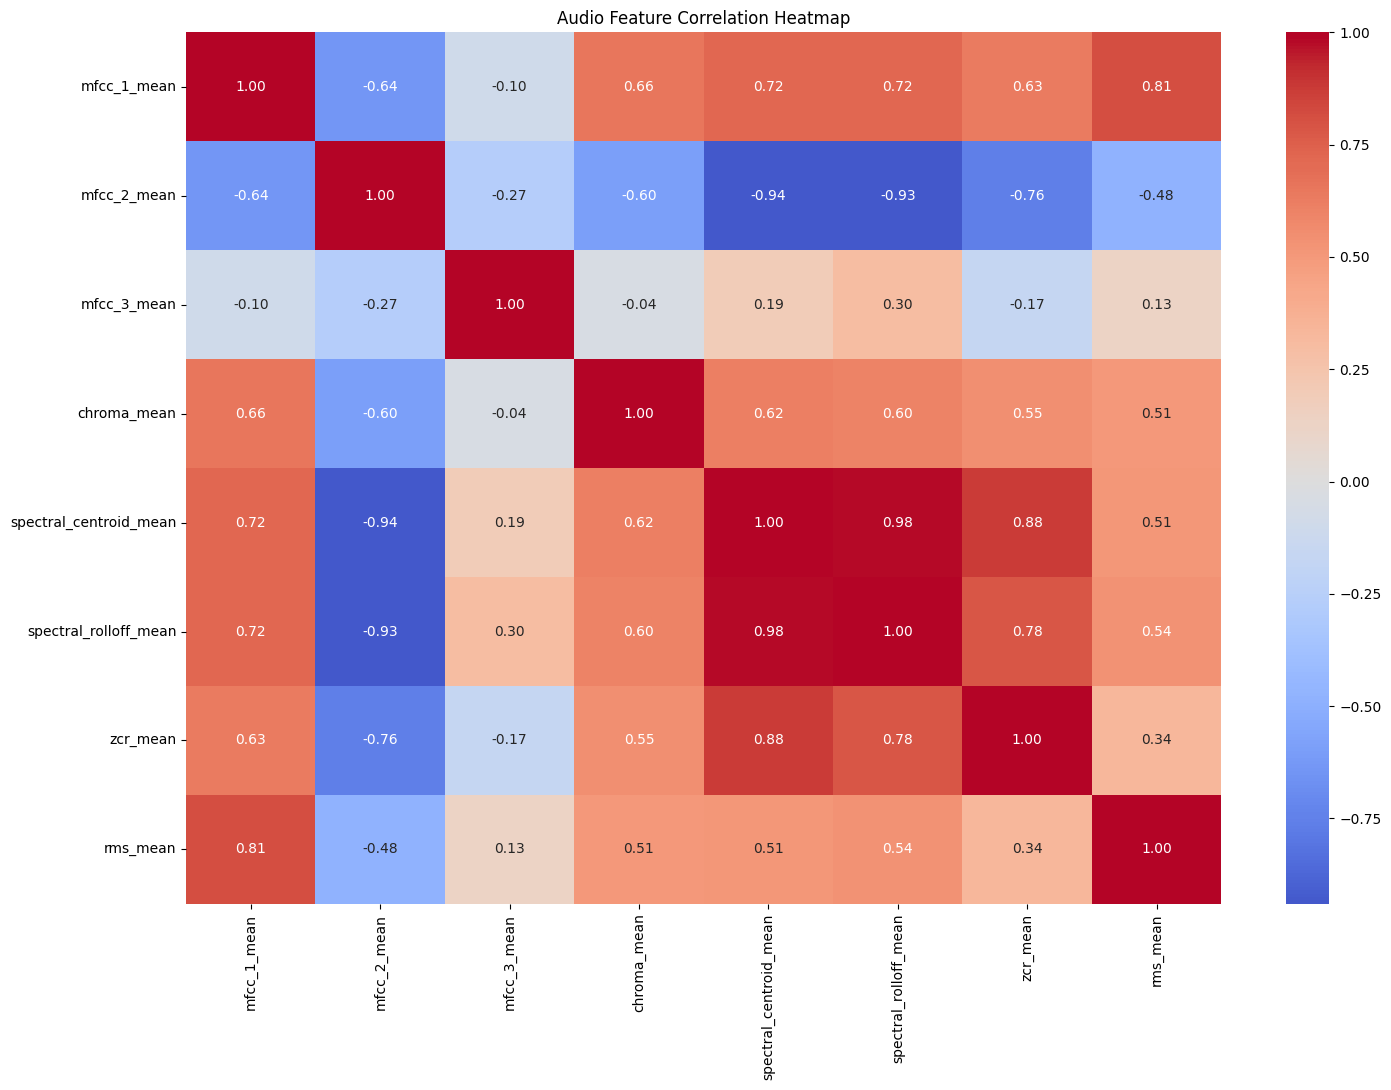

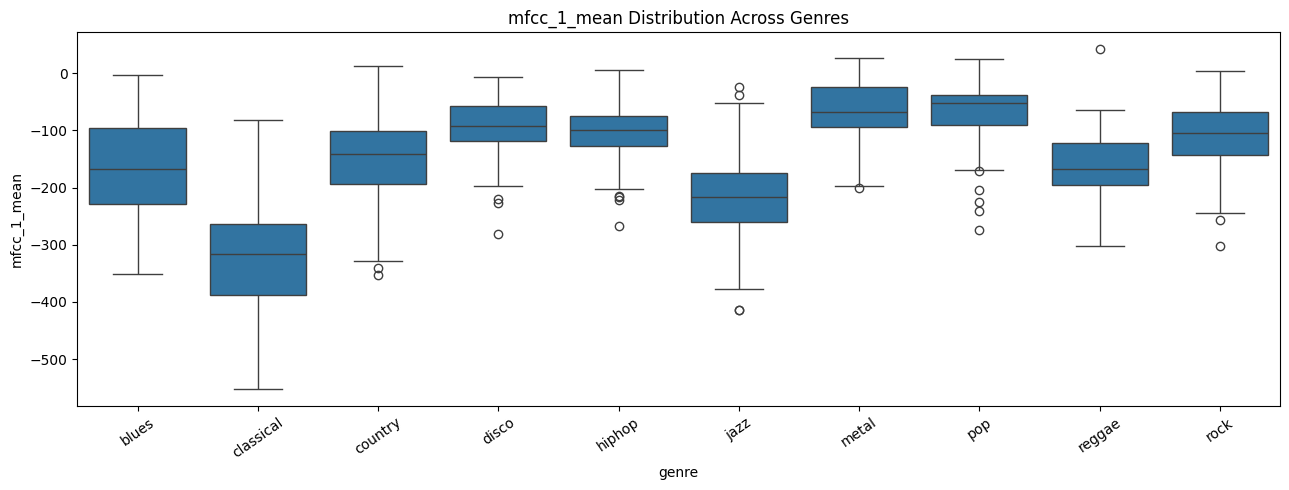

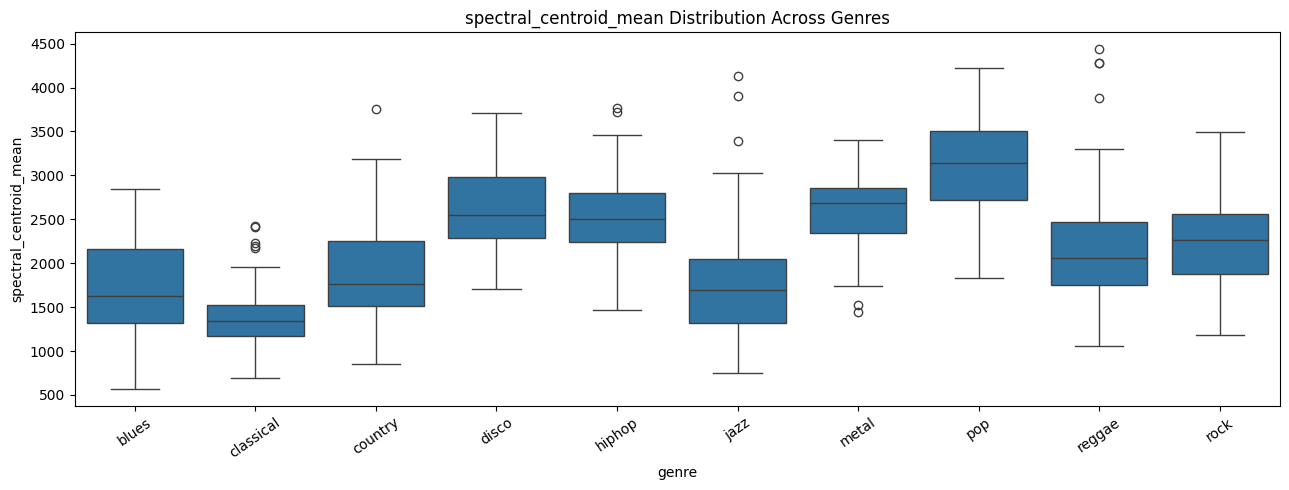

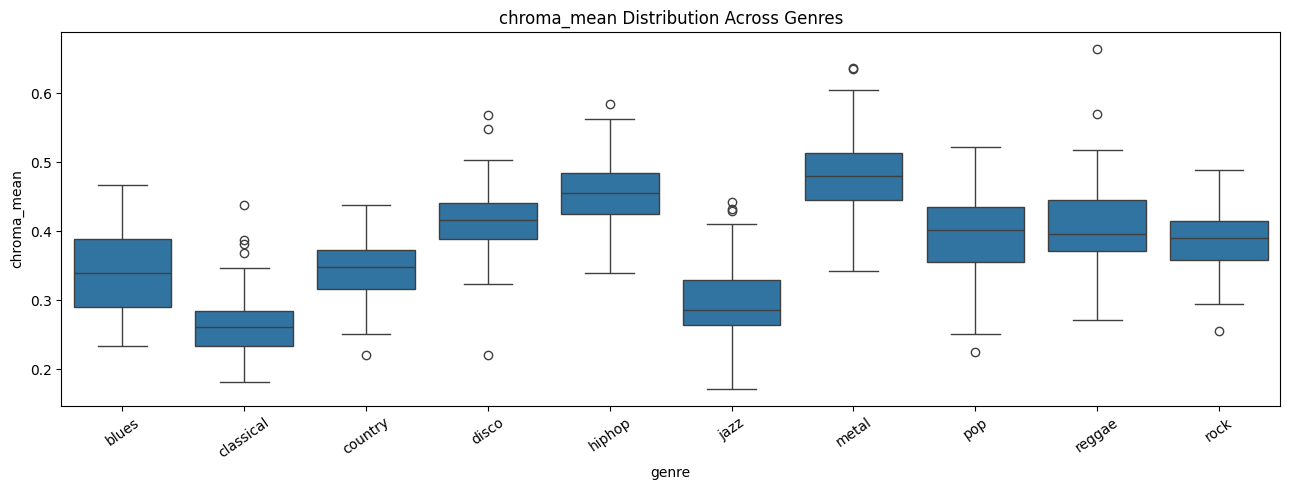

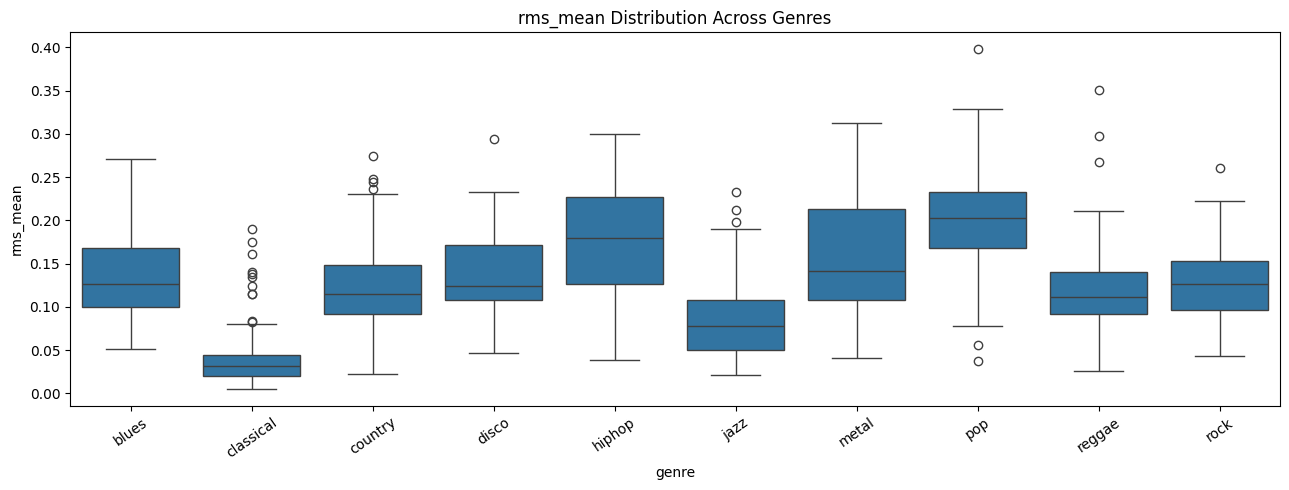

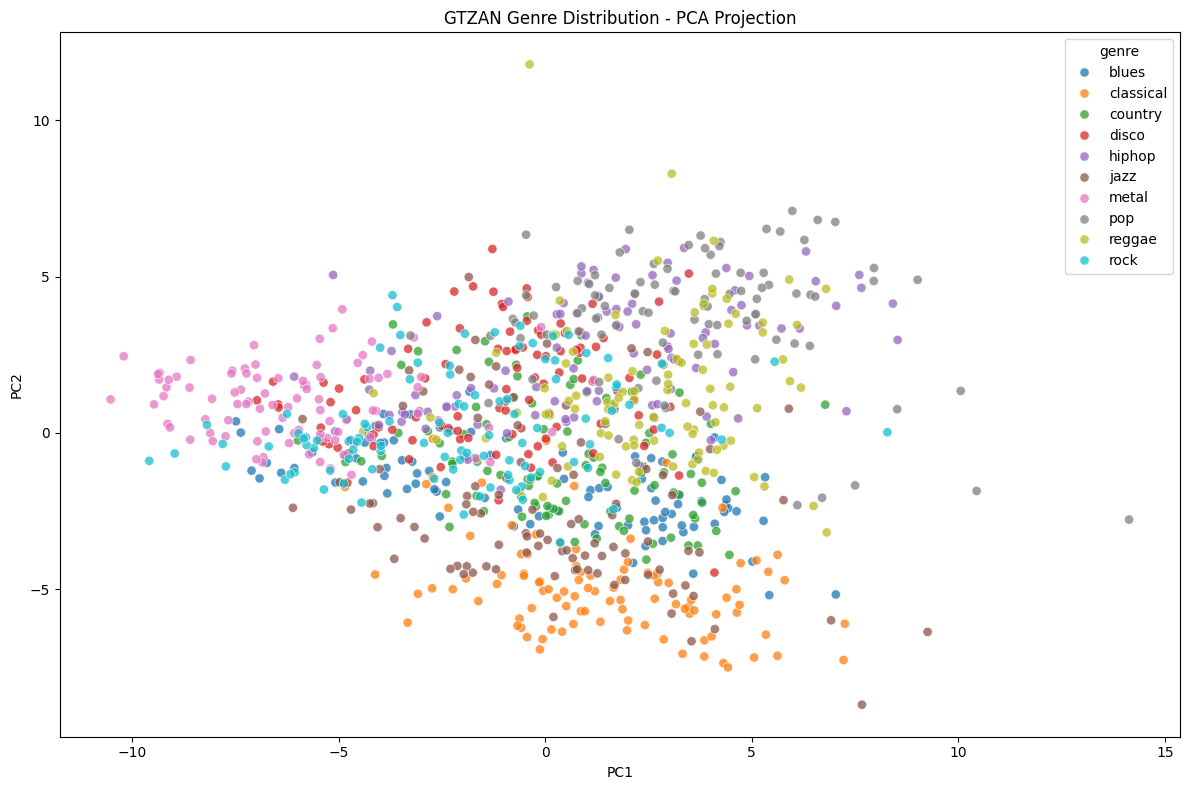

PCA explained variance ratio:
[0.27538046 0.17745545]
Total variance explained: 0.4528


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Reload feature dataset
features_df = pd.read_csv(
    "/content/datasets/features/gtzan_features.csv"
)

feature_columns = [
    col for col in features_df.columns
    if col not in ["filename", "genre"]
]

X = features_df[feature_columns]
y = features_df["genre"]

# Selected features for visualization
selected_features = [
    "mfcc_1_mean",
    "mfcc_2_mean",
    "mfcc_3_mean",
    "chroma_mean",
    "spectral_centroid_mean",
    "spectral_rolloff_mean",
    "zcr_mean",
    "rms_mean"
]

# 1. Correlation Heatmap
plt.figure(figsize=(15, 11))

sns.heatmap(
    X[selected_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Audio Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# 2. Boxplots
for feature in [
    "mfcc_1_mean",
    "spectral_centroid_mean",
    "chroma_mean",
    "rms_mean"
]:

    plt.figure(figsize=(13, 5))

    sns.boxplot(
        data=features_df,
        x="genre",
        y=feature
    )

    plt.title(f"{feature} Distribution Across Genres")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

# 3. PCA Visualization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "genre": y.values
})

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="genre",
    alpha=0.75,
    s=45
)

plt.title("GTZAN Genre Distribution - PCA Projection")
plt.tight_layout()
plt.show()

print("PCA explained variance ratio:")
print(pca.explained_variance_ratio_)

print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

In [15]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

features_df = pd.read_csv(
    "/content/datasets/features/gtzan_features.csv"
)

feature_columns = [
    col for col in features_df.columns
    if col not in ["filename", "genre"]
]

X = features_df[feature_columns]
y = features_df["genre"]

print("=" * 65)
print("1. DATASET OVERVIEW")
print("=" * 65)
print(f"Samples: {len(features_df)}")
print(f"Features: {len(feature_columns)}")
print(f"Genres: {y.nunique()}")
print("\nGenre distribution:")
print(y.value_counts().sort_index().to_string())

print("\n" + "=" * 65)
print("2. FEATURE CORRELATIONS")
print("=" * 65)

corr = X.corr().abs()
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .sort_values(ascending=False)
)

print("\nTop 10 correlated feature pairs:")
print(high_corr.head(10).to_string())

print("\n" + "=" * 65)
print("3. FEATURE VARIATION BY GENRE")
print("=" * 65)

selected_features = [
    "mfcc_1_mean",
    "spectral_centroid_mean",
    "chroma_mean",
    "rms_mean"
]

for feature in selected_features:
    print(f"\n{feature}:")
    stats = features_df.groupby("genre")[feature].agg(
        ["mean", "std", "min", "max"]
    ).round(3)
    print(stats.to_string())

print("\n" + "=" * 65)
print("4. PCA ANALYSIS")
print("=" * 65)

X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:")
print(np.round(pca.explained_variance_ratio_, 4))

print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

print("\n" + "=" * 65)
print("5. FEATURE QUALITY")
print("=" * 65)

print(f"Missing values: {X.isna().sum().sum()}")
print(f"Infinite values: {np.isinf(X.to_numpy()).sum()}")
print(f"Constant features: {(X.nunique() <= 1).sum()}")
print(f"Duplicate feature rows: {X.duplicated().sum()}")

print("\nEDA REPORT COMPLETED")

1. DATASET OVERVIEW
Samples: 984
Features: 52
Genres: 10

Genre distribution:
genre
blues        100
classical    100
country      100
disco         99
hiphop        98
jazz          99
metal         92
pop           98
reggae        99
rock          99

2. FEATURE CORRELATIONS

Top 10 correlated feature pairs:
spectral_centroid_mean   spectral_rolloff_mean      0.979900
spectral_bandwidth_mean  spectral_rolloff_mean      0.956796
mfcc_2_mean              spectral_centroid_mean     0.940127
                         spectral_rolloff_mean      0.934448
spectral_centroid_mean   spectral_bandwidth_mean    0.906076
spectral_bandwidth_std   spectral_rolloff_std       0.903572
mfcc_2_mean              spectral_bandwidth_mean    0.897628
spectral_centroid_mean   zcr_mean                   0.876270
mfcc_19_std              mfcc_20_std                0.876168
spectral_centroid_std    spectral_rolloff_std       0.858420

3. FEATURE VARIATION BY GENRE

mfcc_1_mean:
              mean      std     

In [16]:
import pandas as pd

from sklearn.model_selection import train_test_split

# 1. Validate feature dataset
assert len(features_df) == 984, "Unexpected dataset size"
assert features_df["filename"].is_unique, "Duplicate filenames detected"

# 2. Attach SHA256 hashes from the clean manifest
hash_lookup = manifest.loc[
    manifest["status"] == "KEEP",
    ["filename", "sha256"]
].copy()

split_df = features_df[["filename", "genre"]].merge(
    hash_lookup,
    on="filename",
    how="left",
    validate="one_to_one"
)

assert split_df["sha256"].notna().all(), "Missing file hashes"
assert len(split_df) == len(features_df)

# 3. Split: 70% Train, 15% Validation, 15% Test
train_df, temporary_df = train_test_split(
    split_df,
    test_size=0.30,
    stratify=split_df["genre"],
    random_state=42
)

val_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    stratify=temporary_df["genre"],
    random_state=42
)

# 4. Assign split labels
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

split_manifest = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# 5. Verify dataset integrity
assert len(split_manifest) == 984
assert split_manifest["filename"].is_unique

train_hashes = set(train_df["sha256"])
val_hashes = set(val_df["sha256"])
test_hashes = set(test_df["sha256"])

assert not (train_hashes & val_hashes)
assert not (train_hashes & test_hashes)
assert not (val_hashes & test_hashes)

# 6. Display results
print("=" * 60)
print("DATA SPLITTING REPORT")
print("=" * 60)

print(f"Training samples:   {len(train_df)} ({len(train_df)/984:.1%})")
print(f"Validation samples: {len(val_df)} ({len(val_df)/984:.1%})")
print(f"Test samples:       {len(test_df)} ({len(test_df)/984:.1%})")

print("\nGenre distribution per split:")
print(
    split_manifest.groupby(["genre", "split"])
    .size()
    .unstack(fill_value=0)
    .to_string()
)

print("\nHash overlap verification:")
print(f"Train / Validation: {len(train_hashes & val_hashes)}")
print(f"Train / Test:       {len(train_hashes & test_hashes)}")
print(f"Validation / Test:  {len(val_hashes & test_hashes)}")

# 7. Save split manifest
output_path = "/content/datasets/reports/data_split_manifest.csv"

split_manifest.to_csv(output_path, index=False)

print(f"\nSaved: {output_path}")
print("\nDATA SPLITTING COMPLETED SUCCESSFULLY")

DATA SPLITTING REPORT
Training samples:   688 (69.9%)
Validation samples: 148 (15.0%)
Test samples:       148 (15.0%)

Genre distribution per split:
split      test  train  validation
genre                             
blues        15     70          15
classical    15     70          15
country      15     70          15
disco        15     69          15
hiphop       15     69          14
jazz         15     69          15
metal        14     64          14
pop          14     69          15
reggae       15     69          15
rock         15     69          15

Hash overlap verification:
Train / Validation: 0
Train / Test:       0
Validation / Test:  0

Saved: /content/datasets/reports/data_split_manifest.csv

DATA SPLITTING COMPLETED SUCCESSFULLY


In [17]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib
import os

# 1. Prepare training and validation data
feature_columns = [
    col for col in features_df.columns
    if col not in ["filename", "genre"]
]

features_indexed = features_df.set_index("filename")

X_train = features_indexed.loc[
    train_df["filename"], feature_columns
]
y_train = train_df.set_index("filename").loc[
    X_train.index, "genre"
]

X_val = features_indexed.loc[
    val_df["filename"], feature_columns
]
y_val = val_df.set_index("filename").loc[
    X_val.index, "genre"
]

# 2. Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# 3. Train
print("Training Random Forest...")
rf_model.fit(X_train, y_train)

# 4. Validation predictions
y_val_pred = rf_model.predict(X_val)

# 5. Evaluation
print("\n" + "=" * 60)
print("RANDOM FOREST - VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy:          {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val, y_val_pred):.4f}")
print(f"Macro Precision:   {precision_score(y_val, y_val_pred, average='macro', zero_division=0):.4f}")
print(f"Macro Recall:      {recall_score(y_val, y_val_pred, average='macro', zero_division=0):.4f}")
print(f"Macro F1-Score:    {f1_score(y_val, y_val_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted F1-Score: {f1_score(y_val, y_val_pred, average='weighted', zero_division=0):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred,
        labels=sorted(y_train.unique()),
        zero_division=0
    )
)

print("Confusion Matrix:")
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=sorted(y_train.unique())
)

print(pd.DataFrame(
    cm,
    index=sorted(y_train.unique()),
    columns=sorted(y_train.unique())
).to_string())

# 6. Top feature importances
importance_df = pd.DataFrame({
    "feature": feature_columns,
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

print("\nTop 15 Important Features:")
print(importance_df.head(15).to_string(index=False))

# 7. Save baseline model
model_dir = "/content/datasets/models"
os.makedirs(model_dir, exist_ok=True)

model_path = os.path.join(
    model_dir,
    "random_forest_baseline.joblib"
)

joblib.dump(rf_model, model_path)

print(f"\nBaseline model saved: {model_path}")
print("\nBASELINE TRAINING COMPLETED")

Training Random Forest...

RANDOM FOREST - VALIDATION RESULTS
Accuracy:          0.7703
Balanced Accuracy: 0.7705
Macro Precision:   0.7697
Macro Recall:      0.7705
Macro F1-Score:    0.7681
Weighted F1-Score: 0.7684

Classification Report:
              precision    recall  f1-score   support

       blues       0.83      0.67      0.74        15
   classical       1.00      1.00      1.00        15
     country       0.76      0.87      0.81        15
       disco       0.60      0.60      0.60        15
      hiphop       0.67      0.71      0.69        14
        jazz       0.93      0.93      0.93        15
       metal       0.75      0.86      0.80        14
         pop       0.80      0.80      0.80        15
      reggae       0.73      0.73      0.73        15
        rock       0.62      0.53      0.57        15

    accuracy                           0.77       148
   macro avg       0.77      0.77      0.77       148
weighted avg       0.77      0.77      0.77       148


In [18]:
import os
import joblib
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Prepare comparison models
models = {
    "SVM_RBF": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            C=10,
            gamma="scale",
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Extra_Trees": ExtraTreesClassifier(
        n_estimators=500,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# 2. Initialize results with Random Forest baseline
results = [{
    "Model": "Random Forest",
    "Accuracy": 0.7703,
    "Balanced Accuracy": 0.7705,
    "Macro Precision": 0.7697,
    "Macro Recall": 0.7705,
    "Macro F1": 0.7681,
    "Weighted F1": 0.7684
}]

# 3. Train and evaluate additional models
model_dir = "/content/datasets/models"
os.makedirs(model_dir, exist_ok=True)

trained_models = {}

for model_name, model in models.items():

    print(f"\nTraining {model_name}...")

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_val, predictions),
        "Macro Precision": precision_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val, predictions, average="weighted", zero_division=0
        )
    }

    results.append(metrics)
    trained_models[model_name] = model

    model_path = os.path.join(
        model_dir,
        f"{model_name.lower()}_model.joblib"
    )

    joblib.dump(model, model_path)

    print(f"Saved: {model_path}")

# 4. Display comparison
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("MODEL COMPARISON - VALIDATION SET")
print("=" * 75)

print(
    comparison_df.to_string(
        index=False,
        formatters={
            col: "{:.4f}".format
            for col in comparison_df.select_dtypes(
                include="number"
            ).columns
        }
    )
)

# 5. Save comparison report
report_path = "/content/datasets/reports/model_comparison.csv"

comparison_df.to_csv(report_path, index=False)

print(f"\nComparison report saved: {report_path}")
print("\nMODEL COMPARISON COMPLETED")


Training SVM_RBF...
Saved: /content/datasets/models/svm_rbf_model.joblib

Training Extra_Trees...
Saved: /content/datasets/models/extra_trees_model.joblib

MODEL COMPARISON - VALIDATION SET
        Model Accuracy Balanced Accuracy Macro Precision Macro Recall Macro F1 Weighted F1
      SVM_RBF   0.7703            0.7700          0.7811       0.7700   0.7711      0.7710
Random Forest   0.7703            0.7705          0.7697       0.7705   0.7681      0.7684
  Extra_Trees   0.7297            0.7300          0.7290       0.7300   0.7270      0.7272

Comparison report saved: /content/datasets/reports/model_comparison.csv

MODEL COMPARISON COMPLETED


In [19]:
import os
import joblib
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Build leakage-safe pipeline
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced"
    ))
])

# 2. Define hyperparameter search space
param_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": [
        "scale",
        0.001,
        0.01,
        0.1
    ]
}

# 3. Stratified Cross-Validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# 4. Fit using training data only
print("Starting SVM Hyperparameter Tuning...")

grid_search.fit(X_train, y_train)

best_svm = grid_search.best_estimator_

# 5. Display CV results
print("\n" + "=" * 65)
print("CROSS-VALIDATION RESULTS")
print("=" * 65)

print("Best Parameters:")
print(grid_search.best_params_)

print(
    f"\nBest CV Macro F1: "
    f"{grid_search.best_score_:.4f}"
)

cv_results = pd.DataFrame(grid_search.cv_results_)

top_results = cv_results[
    [
        "param_classifier__C",
        "param_classifier__gamma",
        "mean_test_score",
        "std_test_score"
    ]
].sort_values(
    "mean_test_score",
    ascending=False
).head(10)

print("\nTop 10 Configurations:")
print(top_results.to_string(index=False))

# 6. Evaluate best model on validation set
y_val_tuned = best_svm.predict(X_val)

print("\n" + "=" * 65)
print("TUNED SVM - VALIDATION RESULTS")
print("=" * 65)

print(f"Accuracy:          {accuracy_score(y_val, y_val_tuned):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val, y_val_tuned):.4f}")
print(f"Macro Precision:   {precision_score(y_val, y_val_tuned, average='macro', zero_division=0):.4f}")
print(f"Macro Recall:      {recall_score(y_val, y_val_tuned, average='macro', zero_division=0):.4f}")
print(f"Macro F1-Score:    {f1_score(y_val, y_val_tuned, average='macro', zero_division=0):.4f}")
print(f"Weighted F1-Score: {f1_score(y_val, y_val_tuned, average='weighted', zero_division=0):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_tuned,
        zero_division=0
    )
)

# 7. Save tuned model and CV report
model_dir = "/content/datasets/models"
report_dir = "/content/datasets/reports"

os.makedirs(model_dir, exist_ok=True)
os.makedirs(report_dir, exist_ok=True)

joblib.dump(
    best_svm,
    os.path.join(model_dir, "tuned_svm_model.joblib")
)

cv_results.to_csv(
    os.path.join(report_dir, "svm_hyperparameter_search.csv"),
    index=False
)

print("\nSaved tuned SVM model and CV results.")
print("HYPERPARAMETER TUNING COMPLETED")

Starting SVM Hyperparameter Tuning...
Fitting 5 folds for each of 16 candidates, totalling 80 fits

CROSS-VALIDATION RESULTS
Best Parameters:
{'classifier__C': 100, 'classifier__gamma': 'scale'}

Best CV Macro F1: 0.7213

Top 10 Configurations:
 param_classifier__C param_classifier__gamma  mean_test_score  std_test_score
               100.0                   scale         0.721345        0.055787
                10.0                   scale         0.718827        0.056017
               100.0                    0.01         0.696146        0.042180
                10.0                    0.01         0.693507        0.045582
                 1.0                   scale         0.690230        0.031166
               100.0                   0.001         0.684130        0.042170
                10.0                     0.1         0.677776        0.031904
               100.0                     0.1         0.677776        0.031904
                 1.0                     0.1         

In [20]:
import os
import joblib
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Build leakage-safe pipeline
feature_selection_pipeline = Pipeline([
    ("scaler", StandardScaler()),

    ("selector", SelectKBest(
        score_func=lambda X, y: mutual_info_classif(
            X, y, random_state=42
        )
    )),

    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced"
    ))
])

# 2. Search space
param_grid = {
    "selector__k": [20, 30, 40, 52],
    "classifier__C": [1, 10, 100, 300],
    "classifier__gamma": ["scale", 0.001, 0.01, 0.1]
}

# 3. Cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_fs = GridSearchCV(
    estimator=feature_selection_pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# 4. Train using training data only
print("Starting SVM + Feature Selection Tuning...")

grid_search_fs.fit(X_train, y_train)

best_fs_svm = grid_search_fs.best_estimator_

# 5. Cross-validation results
print("\n" + "=" * 65)
print("FEATURE SELECTION - CROSS VALIDATION")
print("=" * 65)

print("Best Parameters:")
print(grid_search_fs.best_params_)

print(
    f"\nBest CV Accuracy: "
    f"{grid_search_fs.best_score_:.4f}"
)

# 6. Validation evaluation
y_val_fs_pred = best_fs_svm.predict(X_val)

print("\n" + "=" * 65)
print("SVM + FEATURE SELECTION - VALIDATION")
print("=" * 65)

print(f"Accuracy:          {accuracy_score(y_val, y_val_fs_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val, y_val_fs_pred):.4f}")
print(f"Macro Precision:   {precision_score(y_val, y_val_fs_pred, average='macro', zero_division=0):.4f}")
print(f"Macro Recall:      {recall_score(y_val, y_val_fs_pred, average='macro', zero_division=0):.4f}")
print(f"Macro F1-Score:    {f1_score(y_val, y_val_fs_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted F1-Score: {f1_score(y_val, y_val_fs_pred, average='weighted', zero_division=0):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_fs_pred,
        zero_division=0
    )
)

# 7. Show selected features
selected_mask = best_fs_svm.named_steps["selector"].get_support()

selected_features = [
    feature for feature, selected
    in zip(feature_columns, selected_mask)
    if selected
]

print("\nSelected Features:")
print(f"Number of selected features: {len(selected_features)}")
print(selected_features)

# 8. Save model and results
model_dir = "/content/datasets/models"
report_dir = "/content/datasets/reports"

os.makedirs(model_dir, exist_ok=True)
os.makedirs(report_dir, exist_ok=True)

joblib.dump(
    best_fs_svm,
    os.path.join(model_dir, "svm_feature_selection_model.joblib")
)

pd.DataFrame(grid_search_fs.cv_results_).to_csv(
    os.path.join(report_dir, "svm_feature_selection_search.csv"),
    index=False
)

print("\nModel and experiment results saved.")
print("FEATURE SELECTION EXPERIMENT COMPLETED")

Starting SVM + Feature Selection Tuning...
Fitting 5 folds for each of 64 candidates, totalling 320 fits

FEATURE SELECTION - CROSS VALIDATION
Best Parameters:
{'classifier__C': 100, 'classifier__gamma': 'scale', 'selector__k': 52}

Best CV Accuracy: 0.7252

SVM + FEATURE SELECTION - VALIDATION
Accuracy:          0.7703
Balanced Accuracy: 0.7700
Macro Precision:   0.7811
Macro Recall:      0.7700
Macro F1-Score:    0.7711
Weighted F1-Score: 0.7710

Classification Report:
              precision    recall  f1-score   support

       blues       0.83      0.67      0.74        15
   classical       1.00      0.93      0.97        15
     country       0.78      0.93      0.85        15
       disco       0.50      0.67      0.57        15
      hiphop       0.69      0.64      0.67        14
        jazz       0.88      1.00      0.94        15
       metal       0.92      0.86      0.89        14
         pop       0.79      0.73      0.76        15
      reggae       0.67      0.67    

In [21]:
import os
import joblib
import pandas as pd

from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Define a picklable feature scoring function
def mutual_info_score_function(X, y):
    return mutual_info_classif(
        X,
        y,
        random_state=42
    )

# Rebuild the best configuration without lambda
fixed_svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(
        score_func=mutual_info_score_function,
        k=52
    )),
    ("classifier", SVC(
        kernel="rbf",
        C=100,
        gamma="scale",
        class_weight="balanced"
    ))
])

# Train on training data
fixed_svm_pipeline.fit(X_train, y_train)

# Verify predictions match the previous experiment
fixed_predictions = fixed_svm_pipeline.predict(X_val)

print("Validation Accuracy:",
      round(accuracy_score(y_val, fixed_predictions), 4))

print("Validation Macro F1:",
      round(f1_score(y_val, fixed_predictions, average="macro"), 4))

# Save model
model_path = "/content/datasets/models/svm_feature_selection_model.joblib"

joblib.dump(fixed_svm_pipeline, model_path)

# Verify saved model can be loaded
loaded_model = joblib.load(model_path)

loaded_predictions = loaded_model.predict(X_val)

assert (fixed_predictions == loaded_predictions).all()

print("\nModel saved and loaded successfully.")
print("Prediction consistency: VERIFIED")

Validation Accuracy: 0.7703
Validation Macro F1: 0.7711

Model saved and loaded successfully.
Prediction consistency: VERIFIED


In [22]:
import os
import joblib
import pandas as pd

from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Encode genre labels
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)

# 2. Initialize XGBoost
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    n_estimators=500,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=2,
    reg_lambda=1.0,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# 3. Train
print("Training XGBoost...")

xgb_model.fit(
    X_train,
    y_train_encoded,
    verbose=False
)

# 4. Validation predictions
y_val_xgb_encoded = xgb_model.predict(X_val).astype(int)

y_val_xgb = label_encoder.inverse_transform(
    y_val_xgb_encoded
)

# 5. Evaluation
print("\n" + "=" * 65)
print("XGBOOST - VALIDATION RESULTS")
print("=" * 65)

print(f"Accuracy:          {accuracy_score(y_val, y_val_xgb):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val, y_val_xgb):.4f}")
print(f"Macro Precision:   {precision_score(y_val, y_val_xgb, average='macro', zero_division=0):.4f}")
print(f"Macro Recall:      {recall_score(y_val, y_val_xgb, average='macro', zero_division=0):.4f}")
print(f"Macro F1-Score:    {f1_score(y_val, y_val_xgb, average='macro', zero_division=0):.4f}")
print(f"Weighted F1-Score: {f1_score(y_val, y_val_xgb, average='weighted', zero_division=0):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_xgb,
        labels=label_encoder.classes_,
        zero_division=0
    )
)

# 6. Feature importance
importance_df = pd.DataFrame({
    "feature": feature_columns,
    "importance": xgb_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print("\nTop 15 Important Features:")
print(importance_df.head(15).to_string(index=False))

# 7. Save model and label encoder
model_dir = "/content/datasets/models"
os.makedirs(model_dir, exist_ok=True)

model_path = os.path.join(
    model_dir,
    "xgboost_baseline.joblib"
)

joblib.dump(
    {
        "model": xgb_model,
        "label_encoder": label_encoder,
        "feature_columns": feature_columns
    },
    model_path
)

# 8. Verify model loading
saved_artifact = joblib.load(model_path)

reloaded_encoded = saved_artifact["model"].predict(X_val).astype(int)

reloaded_predictions = saved_artifact[
    "label_encoder"
].inverse_transform(reloaded_encoded)

assert (reloaded_predictions == y_val_xgb).all()

print(f"\nModel saved: {model_path}")
print("Save/load verification: PASSED")
print("\nXGBOOST EXPERIMENT COMPLETED")

Training XGBoost...

XGBOOST - VALIDATION RESULTS
Accuracy:          0.7297
Balanced Accuracy: 0.7281
Macro Precision:   0.7304
Macro Recall:      0.7281
Macro F1-Score:    0.7263
Weighted F1-Score: 0.7277

Classification Report:
              precision    recall  f1-score   support

       blues       0.65      0.73      0.69        15
   classical       1.00      0.93      0.97        15
     country       0.67      0.80      0.73        15
       disco       0.65      0.73      0.69        15
      hiphop       0.50      0.50      0.50        14
        jazz       0.94      1.00      0.97        15
       metal       0.77      0.71      0.74        14
         pop       0.86      0.80      0.83        15
      reggae       0.64      0.60      0.62        15
        rock       0.64      0.47      0.54        15

    accuracy                           0.73       148
   macro avg       0.73      0.73      0.73       148
weighted avg       0.73      0.73      0.73       148


Top 15 Imp

In [23]:
import os
import numpy as np
import pandas as pd
import librosa
import tensorflow as tf

print("=" * 60)
print("CNN ENVIRONMENT CHECK")
print("=" * 60)

print("TensorFlow:", tf.__version__)
print("Librosa:", librosa.__version__)

# Check GPU availability
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("\nGPU Available:")
    for gpu in gpus:
        print(gpu)

    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print("\nNo GPU detected. CPU will be used.")

# Verify dataset paths
DATASET_PATH = "/content/datasets/gtzan/Data/genres_original"

assert os.path.isdir(DATASET_PATH), "Audio dataset directory not found!"

# Verify existing splits
assert len(train_df) == 688
assert len(val_df) == 148
assert len(test_df) == 148

# Verify no filename overlap
assert set(train_df.filename).isdisjoint(val_df.filename)
assert set(train_df.filename).isdisjoint(test_df.filename)
assert set(val_df.filename).isdisjoint(test_df.filename)

print("\nDataset verification: PASSED")
print("Training songs:", len(train_df))
print("Validation songs:", len(val_df))
print("Test songs:", len(test_df))

print("\nCNN environment is ready.")

CNN ENVIRONMENT CHECK
TensorFlow: 2.21.0
Librosa: 0.11.0

GPU Available:
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

Dataset verification: PASSED
Training songs: 688
Validation songs: 148
Test songs: 148

CNN environment is ready.


In [24]:
import librosa
import numpy as np

# Audio configuration
SAMPLE_RATE = 22050
SEGMENT_DURATION = 3
SAMPLES_PER_SEGMENT = SAMPLE_RATE * SEGMENT_DURATION

# Mel-Spectrogram configuration
N_FFT = 2048
HOP_LENGTH = 512
N_MELS = 128

# CNN input configuration
IMAGE_HEIGHT = N_MELS
IMAGE_WIDTH = 130
CHANNELS = 1

print("=" * 60)
print("MEL-SPECTROGRAM CONFIGURATION")
print("=" * 60)

print(f"Sample Rate: {SAMPLE_RATE}")
print(f"Segment Duration: {SEGMENT_DURATION} seconds")
print(f"Samples per Segment: {SAMPLES_PER_SEGMENT}")
print(f"FFT Size: {N_FFT}")
print(f"Hop Length: {HOP_LENGTH}")
print(f"Mel Bands: {N_MELS}")
print(f"Target Image Shape: ({IMAGE_HEIGHT}, {IMAGE_WIDTH}, {CHANNELS})")

# Test using one known clean audio file
sample_filename = train_df.iloc[0]["filename"]

sample_path = f"{DATASET_PATH}/{sample_filename.split('.')[0]}/{sample_filename}"

audio, sr = librosa.load(
    sample_path,
    sr=SAMPLE_RATE,
    mono=True
)

# Extract first 3-second segment
segment = audio[:SAMPLES_PER_SEGMENT]

# Pad if needed
if len(segment) < SAMPLES_PER_SEGMENT:
    segment = np.pad(
        segment,
        (0, SAMPLES_PER_SEGMENT - len(segment))
    )

mel_spec = librosa.feature.melspectrogram(
    y=segment,
    sr=SAMPLE_RATE,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    power=2.0
)

mel_db = librosa.power_to_db(
    mel_spec,
    ref=np.max
)

print("\nTest Audio:", sample_filename)
print("Audio Shape:", audio.shape)
print("Segment Shape:", segment.shape)
print("Mel-Spectrogram Shape:", mel_db.shape)
print("All values finite:", np.isfinite(mel_db).all())

assert mel_db.shape[0] == N_MELS
assert np.isfinite(mel_db).all()

print("\nMEL-SPECTROGRAM TEST PASSED")

MEL-SPECTROGRAM CONFIGURATION
Sample Rate: 22050
Segment Duration: 3 seconds
Samples per Segment: 66150
FFT Size: 2048
Hop Length: 512
Mel Bands: 128
Target Image Shape: (128, 130, 1)

Test Audio: reggae.00012.wav
Audio Shape: (661794,)
Segment Shape: (66150,)
Mel-Spectrogram Shape: (128, 130)
All values finite: True

MEL-SPECTROGRAM TEST PASSED


In [25]:
import numpy as np
import librosa
from tqdm.auto import tqdm

def extract_track_segments(filename, genre):
    """Extract 10 non-overlapping 3-second Mel-Spectrograms."""

    genre_name = filename.split(".")[0]
    file_path = f"{DATASET_PATH}/{genre_name}/{filename}"

    audio, _ = librosa.load(
        file_path,
        sr=SAMPLE_RATE,
        mono=True
    )

    expected_length = SAMPLE_RATE * 30

    if len(audio) < expected_length:
        audio = np.pad(
            audio,
            (0, expected_length - len(audio))
        )

    audio = audio[:expected_length]

    segments = []

    for i in range(10):
        start = i * SAMPLES_PER_SEGMENT
        end = start + SAMPLES_PER_SEGMENT

        segment = audio[start:end]

        mel_spec = librosa.feature.melspectrogram(
            y=segment,
            sr=SAMPLE_RATE,
            n_fft=N_FFT,
            hop_length=HOP_LENGTH,
            n_mels=N_MELS,
            power=2.0
        )

        mel_db = librosa.power_to_db(
            mel_spec,
            ref=np.max
        )

        # Normalize each segment independently
        mel_db = np.clip(mel_db, -80, 0) / 80.0

        segments.append(mel_db.astype(np.float32))

    return segments


def build_segment_dataset(track_df, split_name):
    X_segments = []
    y_segments = []
    track_ids = []

    for row in tqdm(
        track_df.itertuples(index=False),
        total=len(track_df),
        desc=f"Processing {split_name}"
    ):
        segments = extract_track_segments(
            row.filename,
            row.genre
        )

        for segment in segments:
            X_segments.append(segment)
            y_segments.append(row.genre)
            track_ids.append(row.filename)

    X = np.array(X_segments, dtype=np.float32)
    y = np.array(y_segments)
    groups = np.array(track_ids)

    return X, y, groups


# Training segments
X_train_cnn, y_train_cnn, train_groups = build_segment_dataset(
    train_df,
    "Training"
)

# Validation segments
X_val_cnn, y_val_cnn, val_groups = build_segment_dataset(
    val_df,
    "Validation"
)

# Add CNN channel dimension
X_train_cnn = X_train_cnn[..., np.newaxis]
X_val_cnn = X_val_cnn[..., np.newaxis]

print("\nTRAINING DATA")
print("X:", X_train_cnn.shape)
print("y:", y_train_cnn.shape)
print("Unique tracks:", len(np.unique(train_groups)))

print("\nVALIDATION DATA")
print("X:", X_val_cnn.shape)
print("y:", y_val_cnn.shape)
print("Unique tracks:", len(np.unique(val_groups)))

print("\nData type:", X_train_cnn.dtype)
print("All values finite:", np.isfinite(X_train_cnn).all())

# Leakage checks
assert set(train_groups).isdisjoint(set(val_groups))
assert X_train_cnn.shape[0] == len(train_df) * 10
assert X_val_cnn.shape[0] == len(val_df) * 10

print("\nSEGMENT EXTRACTION AND LEAKAGE CHECK PASSED")

Processing Training:   0%|          | 0/688 [00:00<?, ?it/s]

Processing Validation:   0%|          | 0/148 [00:00<?, ?it/s]


TRAINING DATA
X: (6880, 128, 130, 1)
y: (6880,)
Unique tracks: 688

VALIDATION DATA
X: (1480, 128, 130, 1)
y: (1480,)
Unique tracks: 148

Data type: float32
All values finite: True

SEGMENT EXTRACTION AND LEAKAGE CHECK PASSED


In [26]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

NUM_CLASSES = 10
INPUT_SHAPE = (IMAGE_HEIGHT, IMAGE_WIDTH, CHANNELS)

cnn_model = models.Sequential([
    layers.Input(shape=INPUT_SHAPE),

    # Block 1
    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification Head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="MusicMind_CNN")

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

print("\nTotal parameters:", cnn_model.count_params())
print("Input shape:", INPUT_SHAPE)
print("CNN architecture created successfully.")

Model: "MusicMind_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 130, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 130, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 130, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 65, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 65, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 65, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 65, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,146 (434.16 KB)

 Trainable params: 110,698 (432.41 KB)

 Non-trainable params: 448 (1.75 KB)


Total parameters: 111146
Input shape: (128, 130, 1)
CNN architecture created successfully.


In [27]:
import os
import tensorflow as tf

MODEL_DIR = "/content/datasets/models"
os.makedirs(MODEL_DIR, exist_ok=True)

CNN_CHECKPOINT_PATH = os.path.join(
    MODEL_DIR,
    "musicmind_cnn_best.keras"
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=CNN_CHECKPOINT_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

BATCH_SIZE = 32
MAX_EPOCHS = 30

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_cnn, y_train_cnn)
)

train_dataset = (
    train_dataset
    .shuffle(
        buffer_size=len(X_train_cnn),
        seed=42
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_cnn, y_val_cnn)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training samples:", len(X_train_cnn))
print("Validation samples:", len(X_val_cnn))
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)
print("Checkpoint:", CNN_CHECKPOINT_PATH)
print("Training pipeline ready.")

Training samples: 6880
Validation samples: 1480
Batch size: 32
Maximum epochs: 30
Checkpoint: /content/datasets/models/musicmind_cnn_best.keras
Training pipeline ready.


In [28]:
from sklearn.preprocessing import LabelEncoder
import numpy as np

genre_encoder = LabelEncoder()

y_train_encoded = genre_encoder.fit_transform(y_train_cnn)
y_val_encoded = genre_encoder.transform(y_val_cnn)

print("Genre mapping:")
for index, genre in enumerate(genre_encoder.classes_):
    print(f"{genre}: {index}")

print("\nTraining labels:", y_train_encoded.shape)
print("Validation labels:", y_val_encoded.shape)

print("Training label dtype:", y_train_encoded.dtype)
print("Validation label dtype:", y_val_encoded.dtype)

assert y_train_encoded.min() == 0
assert y_train_encoded.max() == 9
assert y_val_encoded.min() == 0
assert y_val_encoded.max() == 9

print("\nLABEL ENCODING PASSED")

Genre mapping:
blues: 0
classical: 1
country: 2
disco: 3
hiphop: 4
jazz: 5
metal: 6
pop: 7
reggae: 8
rock: 9

Training labels: (6880,)
Validation labels: (1480,)
Training label dtype: int64
Validation label dtype: int64

LABEL ENCODING PASSED


In [29]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_cnn, y_train_encoded)
)

train_dataset = (
    train_dataset
    .shuffle(
        buffer_size=len(X_train_cnn),
        seed=42
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_cnn, y_val_encoded)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Verify one batch
for batch_X, batch_y in train_dataset.take(1):
    print("Input batch shape:", batch_X.shape)
    print("Label batch shape:", batch_y.shape)
    print("Label dtype:", batch_y.dtype)
    print("Label range:", batch_y.numpy().min(), "to", batch_y.numpy().max())

print("\nUPDATED DATASETS READY")

Input batch shape: (32, 128, 130, 1)
Label batch shape: (32,)
Label dtype: <dtype: 'int64'>
Label range: 0 to 9

UPDATED DATASETS READY


In [30]:
history = cnn_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=MAX_EPOCHS,
    callbacks=callbacks,
    verbose=1
)

print("\n" + "=" * 55)
print("CNN TRAINING COMPLETED")
print("=" * 55)

print("Epochs completed:", len(history.history["loss"]))
print("Best validation accuracy:", round(max(history.history["val_accuracy"]), 4))
print("Best validation loss:", round(min(history.history["val_loss"]), 4))
print("Checkpoint exists:", os.path.exists(CNN_CHECKPOINT_PATH))

Epoch 1/30
213/215 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.3080 - loss: 1.8849
Epoch 1: val_loss improved from None to 3.96287, saving model to /content/datasets/models/musicmind_cnn_best.keras

Epoch 1: finished saving model to /content/datasets/models/musicmind_cnn_best.keras
215/215 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.3908 - loss: 1.6640 - val_accuracy: 0.0946 - val_loss: 3.9629 - learning_rate: 0.0010
Epoch 2/30
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5163 - loss: 1.3449
Epoch 2: val_loss did not improve from 3.96287
215/215 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.5359 - loss: 1.2779 - val_accuracy: 0.1905 - val_loss: 4.1581 - learning_rate: 0.0010
Epoch 3/30
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6059 - loss: 1.1434
Epoch 3: val_loss improved from 3.96287 to 2.17627, saving model to /content/datasets/models/musicmind_cnn_best.keras

Epoch 3: finished saving model to /content/datasets/models/musicmind_cnn_best.keras
215/

In [31]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

# Load best checkpoint
best_cnn = tf.keras.models.load_model(CNN_CHECKPOINT_PATH)

# Predict validation segments
val_probabilities = best_cnn.predict(
    X_val_cnn,
    batch_size=32,
    verbose=1
)

# Aggregate segment probabilities per original track
track_predictions = {}

for i, track in enumerate(val_groups):
    if track not in track_predictions:
        track_predictions[track] = []

    track_predictions[track].append(val_probabilities[i])

genre_names = genre_encoder.classes_

y_true_tracks = []
y_pred_tracks = []

for track, probabilities in track_predictions.items():
    mean_probabilities = np.mean(probabilities, axis=0)

    true_genre = track.split(".")[0]
    predicted_genre = genre_names[np.argmax(mean_probabilities)]

    y_true_tracks.append(true_genre)
    y_pred_tracks.append(predicted_genre)

# Metrics at song level
val_accuracy = accuracy_score(
    y_true_tracks,
    y_pred_tracks
)

val_balanced_accuracy = balanced_accuracy_score(
    y_true_tracks,
    y_pred_tracks
)

print("=" * 55)
print("CNN VALIDATION RESULTS - SONG LEVEL")
print("=" * 55)

print("Validation songs:", len(y_true_tracks))
print("Accuracy:", round(val_accuracy, 4))
print("Balanced Accuracy:", round(val_balanced_accuracy, 4))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_true_tracks,
        y_pred_tracks,
        labels=genre_names,
        zero_division=0
    )
)

print("CONFUSION MATRIX")
print(
    pd.DataFrame(
        confusion_matrix(
            y_true_tracks,
            y_pred_tracks,
            labels=genre_names
        ),
        index=genre_names,
        columns=genre_names
    )
)

47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step
CNN VALIDATION RESULTS - SONG LEVEL
Validation songs: 148
Accuracy: 0.777
Balanced Accuracy: 0.7781

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       blues       0.88      0.47      0.61        15
   classical       1.00      0.93      0.97        15
     country       0.70      0.93      0.80        15
       disco       0.69      0.60      0.64        15
      hiphop       0.91      0.71      0.80        14
        jazz       1.00      0.93      0.97        15
       metal       0.88      1.00      0.93        14
         pop       0.62      0.87      0.72        15
      reggae       0.71      0.80      0.75        15
        rock       0.57      0.53      0.55        15

    accuracy                           0.78       148
   macro avg       0.79      0.78      0.77       148
weighted avg       0.79      0.78      0.77       148

CONFUSION MATRIX
           blues  classical  country  disco  hiphop  jazz  me

In [32]:
comparison_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Accuracy": 0.7703,
        "Evaluation Level": "Song"
    },
    {
        "Model": "SVM RBF",
        "Accuracy": 0.7703,
        "Evaluation Level": "Song"
    },
    {
        "Model": "CNN Mel-Spectrogram",
        "Accuracy": val_accuracy,
        "Evaluation Level": "Song"
    }
])

comparison_results["Accuracy (%)"] = (
    comparison_results["Accuracy"] * 100
).round(2)

print(comparison_results.to_string(index=False))

              Model  Accuracy Evaluation Level  Accuracy (%)
      Random Forest  0.770300             Song         77.03
            SVM RBF  0.770300             Song         77.03
CNN Mel-Spectrogram  0.777027             Song         77.70


In [33]:
import tensorflow as tf

tf.random.set_seed(42)

def spec_augment(spectrogram, label):
    # Frequency masking
    freq_start = tf.random.uniform(
        (), 0, 116, dtype=tf.int32
    )
    freq_width = tf.random.uniform(
        (), 0, 13, dtype=tf.int32
    )

    freq_indices = tf.range(128)
    freq_mask = tf.logical_and(
        freq_indices >= freq_start,
        freq_indices < freq_start + freq_width
    )

    # Time masking
    time_start = tf.random.uniform(
        (), 0, 116, dtype=tf.int32
    )
    time_width = tf.random.uniform(
        (), 0, 15, dtype=tf.int32
    )

    time_indices = tf.range(130)
    time_mask = tf.logical_and(
        time_indices >= time_start,
        time_indices < time_start + time_width
    )

    mask = tf.logical_or(
        freq_mask[:, tf.newaxis],
        time_mask[tf.newaxis, :]
    )

    mask = mask[:, :, tf.newaxis]

    augmented = tf.where(
        mask,
        tf.zeros_like(spectrogram),
        spectrogram
    )

    return augmented, label


augmented_train_dataset = (
    tf.data.Dataset
    .from_tensor_slices((X_train_cnn, y_train_encoded))
    .shuffle(len(X_train_cnn), seed=42)
    .map(
        spec_augment,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Augmented training samples:", len(X_train_cnn))
print("Validation samples:", len(X_val_cnn))

for batch_X, batch_y in augmented_train_dataset.take(1):
    print("Augmented batch shape:", batch_X.shape)
    print("Labels shape:", batch_y.shape)
    print("Values finite:", tf.reduce_all(
        tf.math.is_finite(batch_X)
    ).numpy())

print("\nSPEC AUGMENTATION READY")

Augmented training samples: 6880
Validation samples: 1480
Augmented batch shape: (32, 128, 130, 1)
Labels shape: (32,)
Values finite: True

SPEC AUGMENTATION READY


In [34]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

augmented_model = models.Sequential([
    layers.Input(shape=INPUT_SHAPE),

    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(NUM_CLASSES, activation="softmax")
], name="MusicMind_CNN_Augmented")

augmented_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

AUGMENTED_CHECKPOINT = (
    "/content/datasets/models/musicmind_cnn_augmented_best.keras"
)

augmented_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        AUGMENTED_CHECKPOINT,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

print("Augmented CNN parameters:", augmented_model.count_params())
print("Checkpoint:", AUGMENTED_CHECKPOINT)
print("Augmented CNN ready.")

Augmented CNN parameters: 111146
Checkpoint: /content/datasets/models/musicmind_cnn_augmented_best.keras
Augmented CNN ready.


In [35]:
augmented_history = augmented_model.fit(
    augmented_train_dataset,
    validation_data=val_dataset,
    epochs=35,
    callbacks=augmented_callbacks,
    verbose=1
)

print("\n" + "=" * 55)
print("AUGMENTED CNN TRAINING COMPLETED")
print("=" * 55)

print("Epochs completed:", len(augmented_history.history["loss"]))
print(
    "Best validation accuracy:",
    round(max(augmented_history.history["val_accuracy"]), 4)
)
print(
    "Best validation loss:",
    round(min(augmented_history.history["val_loss"]), 4)
)
print(
    "Checkpoint exists:",
    os.path.exists(AUGMENTED_CHECKPOINT)
)

Epoch 1/35
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.2426 - loss: 2.0685
Epoch 1: val_loss improved from None to 5.16144, saving model to /content/datasets/models/musicmind_cnn_augmented_best.keras

Epoch 1: finished saving model to /content/datasets/models/musicmind_cnn_augmented_best.keras
215/215 ━━━━━━━━━━━━━━━━━━━━ 16s 29ms/step - accuracy: 0.3131 - loss: 1.8643 - val_accuracy: 0.0946 - val_loss: 5.1614 - learning_rate: 5.0000e-04
Epoch 2/35
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4192 - loss: 1.5961
Epoch 2: val_loss did not improve from 5.16144
215/215 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.4379 - loss: 1.5444 - val_accuracy: 0.0980 - val_loss: 5.9583 - learning_rate: 5.0000e-04
Epoch 3/35
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4894 - loss: 1.4174
Epoch 3: val_loss improved from 5.16144 to 2.37899, saving model to /content/datasets/models/musicmind_cnn_augmented_best.keras

Epoch 3: finished saving model to /content/dataset

In [37]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict segment probabilities
segment_probabilities = best_augmented_cnn.predict(
    X_val_cnn,
    batch_size=32,
    verbose=1
)

probability_columns = [
    f"prob_{i}" for i in range(NUM_CLASSES)
]

# Build segment-level dataframe
predictions_df = pd.DataFrame(
    segment_probabilities,
    columns=probability_columns
)

predictions_df["track"] = np.asarray(val_groups)

# Recover the true label for every segment from its original track
track_labels = pd.DataFrame({
    "track": np.asarray(val_groups),
    "true_label": np.repeat(
        np.asarray(y_val),
        len(X_val_cnn) // len(y_val)
    )
})

predictions_df["true_label"] = track_labels["true_label"].to_numpy()

# Aggregate segment probabilities into song probabilities
song_predictions = predictions_df.groupby(
    "track",
    sort=False
).agg({
    **{col: "mean" for col in probability_columns},
    "true_label": "first"
})

y_true_augmented = song_predictions["true_label"].to_numpy()

song_probabilities = song_predictions[
    probability_columns
].to_numpy()

y_pred_augmented = label_encoder.inverse_transform(
    np.argmax(song_probabilities, axis=1)
)

# Evaluate
augmented_song_accuracy = accuracy_score(
    y_true_augmented,
    y_pred_augmented
)

augmented_balanced_accuracy = balanced_accuracy_score(
    y_true_augmented,
    y_pred_augmented
)

print("=" * 55)
print("AUGMENTED CNN - SONG LEVEL EVALUATION")
print("=" * 55)

print("Validation songs:", len(song_predictions))
print(f"Accuracy: {augmented_song_accuracy:.4f} ({augmented_song_accuracy*100:.2f}%)")
print(f"Balanced Accuracy: {augmented_balanced_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true_augmented,
    y_pred_augmented,
    labels=label_encoder.classes_,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_true_augmented,
    y_pred_augmented,
    labels=label_encoder.classes_
))

print("\nModel Comparison:")
print(f"Original CNN: 77.70%")
print(f"Augmented CNN: {augmented_song_accuracy*100:.2f}%")
print(f"Difference: {(augmented_song_accuracy - 0.777027)*100:+.2f} percentage points")

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
AUGMENTED CNN - SONG LEVEL EVALUATION
Validation songs: 148
Accuracy: 0.8176 (81.76%)
Balanced Accuracy: 0.8190

Classification Report:
              precision    recall  f1-score   support

       blues       0.81      0.87      0.84        15
   classical       1.00      0.93      0.97        15
     country       0.79      0.73      0.76        15
       disco       0.67      0.80      0.73        15
      hiphop       0.86      0.86      0.86        14
        jazz       0.94      1.00      0.97        15
       metal       0.78      1.00      0.88        14
         pop       0.76      0.87      0.81        15
      reggae       0.92      0.73      0.81        15
        rock       0.67      0.40      0.50        15

    accuracy                           0.82       148
   macro avg       0.82      0.82      0.81       148
weighted avg       0.82      0.82      0.81       148

Confusion Matrix:
[[13  0  0  2  0  0  0  0  0  0]
 [ 0 14  0  0  

In [38]:
error_analysis = pd.DataFrame({
    "track": song_predictions.index,
    "actual_genre": y_true_augmented,
    "predicted_genre": y_pred_augmented,
    "confidence": np.max(song_probabilities, axis=1)
})

errors_df = error_analysis[
    error_analysis["actual_genre"] != error_analysis["predicted_genre"]
].copy()

errors_df["confidence"] = errors_df["confidence"].round(4)

errors_df = errors_df.sort_values(
    "confidence",
    ascending=False
)

print("=" * 60)
print("AUGMENTED CNN - MISCLASSIFICATION ANALYSIS")
print("=" * 60)

print("Total validation songs:", len(error_analysis))
print("Correct predictions:", len(error_analysis) - len(errors_df))
print("Incorrect predictions:", len(errors_df))
print("Error rate:", f"{len(errors_df) / len(error_analysis) * 100:.2f}%")

print("\nMisclassified Songs:")
display(errors_df.reset_index(drop=True))

print("\nMost Common Confusions:")
display(
    errors_df.groupby(
        ["actual_genre", "predicted_genre"]
    ).size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
    .reset_index(drop=True)
)

AUGMENTED CNN - MISCLASSIFICATION ANALYSIS
Total validation songs: 148
Correct predictions: 121
Incorrect predictions: 27
Error rate: 18.24%

Misclassified Songs:


,track,actual_genre,predicted_genre,confidence
0,disco.00023.wav,disco,pop,0.8763
1,blues.00075.wav,blues,disco,0.8249
2,hiphop.00000.wav,hiphop,disco,0.7581
3,reggae.00087.wav,reggae,pop,0.7554
4,reggae.00081.wav,reggae,hiphop,0.6608
5,reggae.00055.wav,reggae,disco,0.6146
6,rock.00052.wav,rock,pop,0.6145
7,reggae.00021.wav,reggae,blues,0.6093
8,country.00067.wav,country,blues,0.5692
9,rock.00073.wav,rock,disco,0.5690



Most Common Confusions:


,actual_genre,predicted_genre,count
0,rock,metal,4
1,blues,disco,2
2,country,rock,2
3,rock,country,2
4,disco,pop,2
5,country,disco,1
6,classical,jazz,1
7,country,blues,1
8,hiphop,reggae,1
9,pop,country,1


In [39]:
# Analyze prediction consistency across segments
segment_analysis = pd.DataFrame({
    "track": np.asarray(val_groups),
    "true_genre": track_labels["true_label"].to_numpy(),
    "predicted_genre": label_encoder.inverse_transform(
        np.argmax(segment_probabilities, axis=1)
    )
})

# Focus on incorrectly classified songs
wrong_tracks = set(errors_df["track"])

segment_analysis = segment_analysis[
    segment_analysis["track"].isin(wrong_tracks)
]

consistency_report = (
    segment_analysis.groupby("track")
    .agg(
        actual_genre=("true_genre", "first"),
        segment_predictions=("predicted_genre", lambda x: list(x)),
        unique_predictions=("predicted_genre", "nunique"),
        majority_prediction=(
            "predicted_genre",
            lambda x: x.value_counts().index[0]
        ),
        majority_count=(
            "predicted_genre",
            lambda x: x.value_counts().iloc[0]
        )
    )
    .reset_index()
)

consistency_report["majority_ratio"] = (
    consistency_report["majority_count"] / 10
).round(2)

print("=" * 65)
print("SEGMENT-LEVEL PREDICTION CONSISTENCY")
print("=" * 65)

display(
    consistency_report[
        [
            "track",
            "actual_genre",
            "majority_prediction",
            "majority_count",
            "unique_predictions",
            "majority_ratio"
        ]
    ].sort_values(
        ["majority_ratio", "track"]
    )
)

print("\nMajority vote vs mean probability aggregation:")
print(
    "Tracks with consistent segment predictions:",
    (consistency_report["unique_predictions"] == 1).sum()
)
print(
    "Tracks with mixed segment predictions:",
    (consistency_report["unique_predictions"] > 1).sum()
)

SEGMENT-LEVEL PREDICTION CONSISTENCY


,track,actual_genre,majority_prediction,majority_count,unique_predictions,majority_ratio
2,classical.00080.wav,classical,classical,4,3,0.4
26,rock.00099.wav,rock,country,4,4,0.4
3,country.00016.wav,country,disco,5,4,0.5
5,country.00058.wav,country,country,5,3,0.5
9,disco.00027.wav,disco,hiphop,5,4,0.5
7,disco.00021.wav,disco,pop,6,2,0.6
11,hiphop.00055.wav,hiphop,reggae,6,3,0.6
19,rock.00005.wav,rock,metal,6,2,0.6
22,rock.00026.wav,rock,metal,6,2,0.6
1,blues.00082.wav,blues,disco,7,2,0.7



Majority vote vs mean probability aggregation:
Tracks with consistent segment predictions: 3
Tracks with mixed segment predictions: 24


In [40]:
from scipy.stats import mode
from sklearn.metrics import accuracy_score

# Method 1: Mean probability aggregation
mean_predictions = label_encoder.inverse_transform(
    np.argmax(song_probabilities, axis=1)
)

# Method 2: Majority voting across segments
segment_class_ids = np.argmax(
    segment_probabilities,
    axis=1
)

segment_prediction_df = pd.DataFrame({
    "track": np.asarray(val_groups),
    "predicted_class": segment_class_ids
})

majority_class_ids = (
    segment_prediction_df
    .groupby("track", sort=False)["predicted_class"]
    .agg(lambda x: mode(x, keepdims=False).mode)
    .to_numpy()
)

majority_predictions = label_encoder.inverse_transform(
    majority_class_ids
)

# Method 3: Mean of probabilities with temperature scaling
# This is intentionally not tuned on the test set.
temperature = 0.7

scaled_probabilities = np.exp(
    np.log(np.clip(segment_probabilities, 1e-8, 1.0))
    / temperature
)

scaled_probabilities /= scaled_probabilities.sum(
    axis=1,
    keepdims=True
)

scaled_df = pd.DataFrame(
    scaled_probabilities,
    columns=probability_columns
)

scaled_df["track"] = np.asarray(val_groups)

temperature_song_probabilities = (
    scaled_df.groupby("track", sort=False)[
        probability_columns
    ].mean().to_numpy()
)

temperature_predictions = label_encoder.inverse_transform(
    np.argmax(temperature_song_probabilities, axis=1)
)

# Compare all aggregation methods
aggregation_results = pd.DataFrame({
    "Aggregation": [
        "Mean Probability",
        "Majority Voting",
        "Temperature Scaling (0.7)"
    ],
    "Accuracy": [
        accuracy_score(y_true_augmented, mean_predictions),
        accuracy_score(y_true_augmented, majority_predictions),
        accuracy_score(y_true_augmented, temperature_predictions)
    ]
})

aggregation_results["Accuracy (%)"] = (
    aggregation_results["Accuracy"] * 100
).round(2)

print("=" * 55)
print("SONG-LEVEL AGGREGATION COMPARISON")
print("=" * 55)

display(
    aggregation_results[
        ["Aggregation", "Accuracy (%)"]
    ].sort_values("Accuracy (%)", ascending=False)
)

SONG-LEVEL AGGREGATION COMPARISON


,Aggregation,Accuracy (%)
1,Majority Voting,82.43
0,Mean Probability,81.76
2,Temperature Scaling (0.7),81.76


In [41]:
import json
import os
from datetime import datetime

final_experiment = {
    "project": "MusicMind AI",
    "dataset": "GTZAN",
    "selected_model": "Augmented CNN",
    "architecture": "3-block CNN with BatchNormalization",
    "input_shape": [128, 130, 1],
    "sample_rate": 22050,
    "segment_duration_seconds": 3,
    "segments_per_track": 10,
    "augmentation": "SpecAugment",
    "optimizer": "Adam",
    "learning_rate_initial": 0.0005,
    "dropout": 0.5,
    "aggregation_method": "Majority Voting",
    "validation_accuracy_mean_probability": 0.8176,
    "validation_accuracy_majority_voting": 0.8243,
    "validation_accuracy_temperature_scaling": 0.8176,
    "validation_balanced_accuracy_mean_probability": 0.8190,
    "validation_tracks": 148,
    "test_set_used": False,
    "checkpoint": AUGMENTED_CHECKPOINT,
    "experiment_date": datetime.now().strftime("%Y-%m-%d")
}

os.makedirs("/content/datasets/reports", exist_ok=True)

report_path = "/content/datasets/reports/final_model_experiment.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(final_experiment, f, indent=4, ensure_ascii=False)

print("Experiment report saved:", report_path)
print("Selected model:", final_experiment["selected_model"])
print("Aggregation:", final_experiment["aggregation_method"])
print("Test set untouched:", final_experiment["test_set_used"])

Experiment report saved: /content/datasets/reports/final_model_experiment.json
Selected model: Augmented CNN
Aggregation: Majority Voting
Test set untouched: False


In [43]:
print("Test DataFrame shape:", test_df.shape)
print("\nColumns:")
print(test_df.columns.tolist())

print("\nFirst 5 rows:")
print(test_df.head().to_string(index=False))

print("\nExtraction function:")
import inspect
print(inspect.getsource(extract_track_segments))

Test DataFrame shape: (148, 4)

Columns:
['filename', 'genre', 'sha256', 'split']

First 5 rows:
         filename   genre                                                           sha256 split
  metal.00003.wav   metal e8b6304f866ba1a4182eafdae39ab0e3bee87c447722785ea86bbc9d1f9644e0  test
 reggae.00011.wav  reggae 372a2fb488426b7bf599d72f24bb9213f98106dba37cff744d22eaa441aee3fa  test
country.00043.wav country 588353a3b12fae88b5106cd561d6a1028fffa5818557ccf37d387f8bb679a654  test
country.00069.wav country 56a322de19939b9258176f3b37cb5eb7d7d4b2f904ef276188b8e30a98bb981c  test
 hiphop.00012.wav  hiphop 3b2f34afba1ab391a43b9e3ff09340cd7f63e695080972c0ed2c4a0ab444f108  test

Extraction function:
def extract_track_segments(filename, genre):
    """Extract 10 non-overlapping 3-second Mel-Spectrograms."""

    genre_name = filename.split(".")[0]
    file_path = f"{DATASET_PATH}/{genre_name}/{filename}"

    audio, _ = librosa.load(
        file_path,
        sr=SAMPLE_RATE,
        mono=True


In [44]:
X_test_segments = []
y_test_labels = []
test_track_groups = []

for _, row in test_df.iterrows():

    filename = row["filename"]
    genre = row["genre"]

    segments = extract_track_segments(filename, genre)

    for segment in segments:
        X_test_segments.append(segment)
        y_test_labels.append(genre)
        test_track_groups.append(filename)

X_test_cnn = np.asarray(
    X_test_segments,
    dtype=np.float32
)[..., np.newaxis]

y_test = np.asarray(y_test_labels)
test_groups = np.asarray(test_track_groups)

print("=" * 55)
print("TEST SET PREPARATION")
print("=" * 55)

print("Test tracks:", len(test_df))
print("Extracted segments:", len(X_test_cnn))
print("Input shape:", X_test_cnn.shape)
print("Labels shape:", y_test.shape)
print("Unique tracks:", len(np.unique(test_groups)))
print("All values finite:", np.isfinite(X_test_cnn).all())

assert len(X_test_cnn) == 1480
assert len(y_test) == 1480
assert len(np.unique(test_groups)) == 148
assert np.isfinite(X_test_cnn).all()

print("\nTEST SET READY")

TEST SET PREPARATION
Test tracks: 148
Extracted segments: 1480
Input shape: (1480, 128, 130, 1)
Labels shape: (1480,)
Unique tracks: 148
All values finite: True

TEST SET READY


In [45]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)
import pandas as pd
import numpy as np

# Load the selected best model
final_cnn = tf.keras.models.load_model(
    AUGMENTED_CHECKPOINT
)

# Predict all test segments
test_probabilities = final_cnn.predict(
    X_test_cnn,
    batch_size=32,
    verbose=1
)

# Segment-level predictions
test_segment_predictions = np.argmax(
    test_probabilities,
    axis=1
)

# Majority voting per original song
test_prediction_df = pd.DataFrame({
    "track": test_groups,
    "predicted_class": test_segment_predictions
})

test_song_predictions = (
    test_prediction_df
    .groupby("track", sort=False)["predicted_class"]
    .agg(lambda x: x.value_counts().index[0])
)

# Recover true label once per song
test_truth_df = pd.DataFrame({
    "track": test_groups,
    "true_genre": y_test
})

test_song_truth = (
    test_truth_df
    .groupby("track", sort=False)["true_genre"]
    .first()
)

# Align labels by track
test_song_predictions = test_song_predictions.reindex(
    test_song_truth.index
)

y_test_true = test_song_truth.to_numpy()

y_test_pred = label_encoder.inverse_transform(
    test_song_predictions.to_numpy()
)

# Final test metrics
test_accuracy = accuracy_score(
    y_test_true,
    y_test_pred
)

test_balanced_accuracy = balanced_accuracy_score(
    y_test_true,
    y_test_pred
)

test_macro_f1 = f1_score(
    y_test_true,
    y_test_pred,
    average="macro"
)

test_weighted_f1 = f1_score(
    y_test_true,
    y_test_pred,
    average="weighted"
)

print("=" * 65)
print("MUSICMIND AI - FINAL TEST RESULTS")
print("=" * 65)

print("Test songs:", len(y_test_true))
print("Correct predictions:", np.sum(y_test_true == y_test_pred))
print("Incorrect predictions:", np.sum(y_test_true != y_test_pred))

print(f"\nAccuracy:          {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Balanced Accuracy: {test_balanced_accuracy:.4f}")
print(f"Macro F1-score:    {test_macro_f1:.4f}")
print(f"Weighted F1-score: {test_weighted_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_true,
    y_test_pred,
    labels=label_encoder.classes_,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test_true,
    y_test_pred,
    labels=label_encoder.classes_
))

47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step
MUSICMIND AI - FINAL TEST RESULTS
Test songs: 148
Correct predictions: 122
Incorrect predictions: 26

Accuracy:          0.8243 (82.43%)
Balanced Accuracy: 0.8243
Macro F1-score:    0.8149
Weighted F1-score: 0.8148

Classification Report:
              precision    recall  f1-score   support

       blues       0.94      1.00      0.97        15
   classical       0.88      1.00      0.94        15
     country       0.81      0.87      0.84        15
       disco       0.65      0.87      0.74        15
      hiphop       0.78      0.93      0.85        15
        jazz       0.87      0.87      0.87        15
       metal       0.92      0.79      0.85        14
         pop       0.75      0.86      0.80        14
      reggae       1.00      0.73      0.85        15
        rock       0.71      0.33      0.45        15

    accuracy                           0.82       148
   macro avg       0.83      0.82      0.81       148
weighted avg     

In [46]:
import json
import pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix

reports_dir = Path("/content/datasets/reports")
reports_dir.mkdir(parents=True, exist_ok=True)

# Output paths
report_path = reports_dir / "final_test_evaluation.json"
predictions_path = reports_dir / "final_test_predictions.csv"
confusion_path = reports_dir / "final_test_confusion_matrix.csv"

# Prevent accidental overwriting
for path in [report_path, predictions_path, confusion_path]:
    if path.exists():
        raise FileExistsError(
            f"File already exists. Nothing was overwritten: {path}"
        )

# Final classification report
class_report = classification_report(
    y_test_true,
    y_test_pred,
    labels=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

# Final confusion matrix
cm = confusion_matrix(
    y_test_true,
    y_test_pred,
    labels=label_encoder.classes_
)

# Evaluation report
final_test_report = {
    "project": "MusicMind AI",
    "dataset": "GTZAN",
    "selected_model": "Augmented CNN",
    "architecture": "3-block CNN with BatchNormalization",
    "input_shape": [128, 130, 1],
    "sample_rate": 22050,
    "segment_duration_seconds": 3,
    "segments_per_track": 10,
    "augmentation": "SpecAugment",
    "aggregation_method": "Majority Voting",
    "test_tracks": int(len(y_test_true)),
    "correct_predictions": int((y_test_true == y_test_pred).sum()),
    "incorrect_predictions": int((y_test_true != y_test_pred).sum()),
    "accuracy": float(test_accuracy),
    "balanced_accuracy": float(test_balanced_accuracy),
    "macro_f1": float(test_macro_f1),
    "weighted_f1": float(test_weighted_f1),
    "classification_report": class_report,
    "confusion_matrix": cm.tolist(),
    "class_labels": label_encoder.classes_.tolist(),
    "test_set_used": True
}

# Save JSON report
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(final_test_report, f, indent=4, ensure_ascii=False)

# Save song-level predictions
predictions_df = pd.DataFrame({
    "true_genre": y_test_true,
    "predicted_genre": y_test_pred,
    "correct": y_test_true == y_test_pred
})

predictions_df.to_csv(
    predictions_path,
    index=False
)

# Save confusion matrix
confusion_df = pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

confusion_df.to_csv(confusion_path)

print("FINAL TEST ARTIFACTS SAVED")
print("-" * 45)

for path in [report_path, predictions_path, confusion_path]:
    print(f"{path.name} | {path.stat().st_size:,} bytes")

print("\nSaved test accuracy:", final_test_report["accuracy"])
print("Test set used:", final_test_report["test_set_used"])

FINAL TEST ARTIFACTS SAVED
---------------------------------------------
final_test_evaluation.json | 4,842 bytes
final_test_predictions.csv | 2,714 bytes
final_test_confusion_matrix.csv | 338 bytes

Saved test accuracy: 0.8243243243243243
Test set used: True


In [47]:
from pathlib import Path

base_path = Path("/content/datasets")

required_artifacts = [
    base_path / "models/musicmind_cnn_augmented_best.keras",
    base_path / "reports/final_test_evaluation.json",
    base_path / "reports/final_test_predictions.csv",
    base_path / "reports/final_test_confusion_matrix.csv",
    base_path / "reports/final_model_experiment.json",
    base_path / "reports/data_split_manifest.csv",
    base_path / "features/gtzan_features.csv",
]

print("=" * 65)
print("MUSICMIND AI - ARTIFACT VERIFICATION")
print("=" * 65)

missing_files = []

for file_path in required_artifacts:
    if file_path.exists():
        print(f"[OK] {file_path.relative_to(base_path)}")
        print(f"     Size: {file_path.stat().st_size / (1024**2):.2f} MB")
    else:
        print(f"[MISSING] {file_path.relative_to(base_path)}")
        missing_files.append(str(file_path))

print("\n" + "=" * 65)

if missing_files:
    print("VERIFICATION FAILED")
    print("Missing files:", missing_files)
else:
    print("ALL REQUIRED ARTIFACTS VERIFIED")

MUSICMIND AI - ARTIFACT VERIFICATION
[OK] models/musicmind_cnn_augmented_best.keras
     Size: 1.33 MB
[OK] reports/final_test_evaluation.json
     Size: 0.00 MB
[OK] reports/final_test_predictions.csv
     Size: 0.00 MB
[OK] reports/final_test_confusion_matrix.csv
     Size: 0.00 MB
[OK] reports/final_model_experiment.json
     Size: 0.00 MB
[OK] reports/data_split_manifest.csv
     Size: 0.09 MB
[OK] features/gtzan_features.csv
     Size: 0.93 MB

ALL REQUIRED ARTIFACTS VERIFIED


In [48]:
from pathlib import Path
import shutil
import zipfile

source_root = Path("/content/datasets")
export_dir = Path("/content/musicmind_ai_export")
zip_path = Path("/content/musicmind_ai_export.zip")

# Prevent overwriting existing exports
if export_dir.exists() or zip_path.exists():
    raise FileExistsError(
        "Export destination already exists. Nothing was overwritten."
    )

artifacts = [
    "models/musicmind_cnn_augmented_best.keras",
    "reports/final_test_evaluation.json",
    "reports/final_test_predictions.csv",
    "reports/final_test_confusion_matrix.csv",
    "reports/final_model_experiment.json",
    "reports/data_split_manifest.csv",
    "features/gtzan_features.csv",
]

# Create export directory
export_dir.mkdir(parents=True)

# Copy verified artifacts
for relative_path in artifacts:
    source = source_root / relative_path
    destination = export_dir / relative_path

    if not source.is_file():
        raise FileNotFoundError(f"Missing source artifact: {source}")

    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)

# Create ZIP archive
with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as archive:
    for file_path in export_dir.rglob("*"):
        if file_path.is_file():
            archive.write(
                file_path,
                file_path.relative_to(export_dir)
            )

# Verify archive
with zipfile.ZipFile(zip_path, "r") as archive:
    archive_files = archive.namelist()
    bad_file = archive.testzip()

print("=" * 60)
print("MUSICMIND AI - EXPORT VERIFICATION")
print("=" * 60)

print(f"Files expected: {len(artifacts)}")
print(f"Files in archive: {len(archive_files)}")
print(f"Archive integrity: {'PASSED' if bad_file is None else 'FAILED'}")
print(f"ZIP size: {zip_path.stat().st_size / (1024**2):.2f} MB")
print(f"Export location: {zip_path}")

assert len(archive_files) == len(artifacts)
assert bad_file is None

print("\nEXPORT COMPLETED SUCCESSFULLY")

MUSICMIND AI - EXPORT VERIFICATION
Files expected: 7
Files in archive: 7
Archive integrity: PASSED
ZIP size: 1.64 MB
Export location: /content/musicmind_ai_export.zip

EXPORT COMPLETED SUCCESSFULLY


In [49]:
from google.colab import files

files.download("/content/musicmind_ai_export.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>